# Analyzing the Dataset for Experiment Chapter

In [1]:
import json
import re
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import pandas as pd
import plotly.express as px

## Helper Functions

In [36]:
def modify_session_data(data, name):

    # Modify the structure to include the new label format and place label first
    for key, sessions in data.items():
        # Extract the person number from the key (e.g., P11 becomes 11)
        person_number = re.findall(r'\d+', key)[0]

        for session_index, session in enumerate(sessions):
            for process_index, process_obj in enumerate(session):
                # Create the label: pXX_YY_ZZ
                process_id = f"p{person_number}_{session_index + 1}_{process_index + 1}"

                # Create a new dictionary with 'label' first
                updated_process_obj = {
                    "process_id": process_id,
                    "process": process_obj["process"],
                    "context": process_obj["context"],
                    "dimensions": process_obj["dimensions"]
                }

                # Replace the old process object with the updated one
                session[process_index] = updated_process_obj


    #with open('modified_ptb_mini_session_pretty_v2', 'w') as new_file:
    #    json.dump(output, new_file, indent=2)

    with open(name, 'w') as fp:
        json.dump(data, fp)

def count_dimensions_per_session(data, person_id):
    """
    Counts the occurrence of each dimension for all processes in each session
    and the total number of processes for a given person.

    Parameters:
    - output (dict): The JSON output containing process information for each person.
    - person_id (str): The ID of the person.

    Returns:
    - dict: A dictionary with the counts of dimensions for each session and the total process count.
    """

    if person_id not in data:
        raise ValueError(f"Person ID '{person_id}' not found in output.")

    # Initialize dictionaries to track dimension counts and process totals
    session_dimension_counts = defaultdict(lambda: defaultdict(int))
    session_process_counts = defaultdict(int)

    # Get the sessions for the given person
    sessions = data[person_id]

    # Iterate through each session
    for session_index, session in enumerate(sessions, start=1):
        for process in session:
            # For each process, handle dimension as a list
            dimensions = process['dimensions']

            # If dimension is a list, extract each element and count it
            if isinstance(dimensions, list):
                for dimension in dimensions:
                    session_dimension_counts[session_index][dimension] += 1
            else:
                session_dimension_counts[session_index][dimensions] += 1

            # Count the process
            session_process_counts[session_index] += 1

    # Calculate the total number of processes
    total_processes = sum(session_process_counts.values())

    # Return the results
    return {
        'session_dimension_counts': dict(session_dimension_counts),
        'session_process_counts': dict(session_process_counts),
        'total_processes': total_processes
    }


def compute_processe_plt(data, p_id):
    if p_id not in data:
        raise ValueError(f"Patient ID ' {p_id}' not found in output. ")

    session_counts = defaultdict(int)
    sessions = data[p_id]

    for session_index, session in enumerate(sessions):
        session_counts[session_index + 1] = len(session)

    total_processes = sum(session_counts.values())

    result =   {'session_counts' : dict(session_counts),
                'total_processes': total_processes}

    return result

def compute_processe_plt_all(data):
    """
    Compute the number of processes for each session for all persons in the output.

    Parameters:
    - output (dict): The input output with person IDs as keys and session output as values.

    Returns:
    - result (dict): A dictionary where each key is a person ID, and the value is a dictionary
                     containing session process counts and total processes for that person.
    """
    all_results = {}

    # Iterate over each person in the output
    for p_id, sessions in data.items():
        session_counts = defaultdict(int)

        # Count processes in each session for the current person
        for session_index, session in enumerate(sessions):
            session_counts[session_index + 1] = len(session)  # session_index + 1 to make session numbers start from 1

        # Calculate the total number of processes for this person
        total_processes = sum(session_counts.values())

        # Store the result for this person
        all_results[p_id] = {
            'session_counts': dict(session_counts),
            'total_processes': total_processes
        }

    return all_results



def create_process_plot(data, person_id):
    """
    Generate a bar plot of the number of processes for each session of the given person using Plotly.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes'.
    - person_id (str): The ID of the person whose output is being plotted.
    """
    # Extract session process counts from the input output
    session_process_counts = data['session_counts']

    # Convert the session process output to a pandas DataFrame
    df = pd.DataFrame({
        "Session": list(session_process_counts.keys()),
        "Number of Processes": list(session_process_counts.values()),
        "Patient": [person_id] * len(session_process_counts)
    })

    # Generate a bar chart using plotly express
    fig = px.bar(df, x="Session", y="Number of Processes", color="Patient", barmode="group",
                 title=f"Number of Processes for {person_id} Across Sessions")

    # Update x-axis to ensure session numbers are shown as integers
    fig.update_xaxes(dtick=1)

    # Show the plot
    fig.show()

def create_process_plot_for_all(data):
    """
    Generate bar plots for all persons, showing the number of processes per session, using Plotly facet plots.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes' for each person.
    """
    all_data = []

    # Iterate over each person in the output
    for p_id, person_data in data.items():
        session_process_counts = person_data['session_counts']

        # Create a DataFrame for each person and append it to the list
        df_person = pd.DataFrame({
            "Session": list(session_process_counts.keys()),
            "Number of Processes": list(session_process_counts.values()),
            "Patient": [p_id] * len(session_process_counts)
        })
        all_data.append(df_person)

    # Combine all DataFrames into one
    df_all = pd.concat(all_data)

    # Generate a bar chart with facets for each person
    fig = px.bar(
        df_all,
        x="Session",
        y="Number of Processes",
        color="Patient",
        barmode="group",
        facet_col="Patient",  # Creates separate subplots for each person
        title="Number of Processes for Each Person Across Sessions"
    )


    # Update x-axis to ensure session numbers are shown as integers
    fig.update_xaxes(dtick=1)

    # Adjust layout to make the bars wider
    fig.update_layout(
        bargap=0.001,  # Reduces the gap between bars (0 means no gap, 1 means maximum gap)
        bargroupgap=0.001  # Reduces the gap between bar groups
    )
    # Show the plot
    fig.show()

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_process_plot_for_all_sns(data):
    """
    Generate bar plots for all patients using Seaborn FacetGrid, showing the number of processes per session.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes' for each patient.
    """
    all_data = []

    # Prepare the output
    for p_id, person_data in data.items():
        session_process_counts = person_data['session_counts']
        df_person = pd.DataFrame({
            "Session": list(session_process_counts.keys()),
            "Number of Processes": list(session_process_counts.values()),
            "Patient": [p_id] * len(session_process_counts)
        })
        all_data.append(df_person)

    df_all = pd.concat(all_data)

    # Ensure session is numeric for correct axis handling
    df_all["Session"] = pd.to_numeric(df_all["Session"])

    # Create the FacetGrid with one plot per patient
    g = sns.FacetGrid(df_all, col="Patient", col_wrap=4, sharey=False, height=4, aspect=1.2)
    g.map_dataframe(sns.barplot, x="Session", y="Number of Processes", color="steelblue")

    # Styling
    g.set_titles(col_template="Patient: {col_name}")
    g.set_axis_labels("Session", "Number of Processes")
    for ax in g.axes.flatten():
        ax.set_xticks(sorted(df_all["Session"].unique()))

    plt.tight_layout()
    plt.savefig("number_of_processes_per_session_by_patient.pdf")
    plt.show()



def create_process_plot_for_all_therapist(data):
    """
    Generate bar plots for all persons, showing the number of processes per session, using Plotly facet plots.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes' for each person.
    """
    all_data = []

    # Iterate over each person in the output
    for p_id, person_data in data.items():
        session_process_counts = person_data['session_counts']

        # Create a DataFrame for each person and append it to the list
        df_person = pd.DataFrame({
            "Session": list(session_process_counts.keys()),
            "Number of Processes": list(session_process_counts.values()),
            "Therapist": [p_id] * len(session_process_counts)
        })
        all_data.append(df_person)

    # Combine all DataFrames into one
    df_all = pd.concat(all_data)

    # Generate a bar chart with facets for each person
    fig = px.bar(
        df_all,
        x="Session",
        y="Number of Processes",
        color="Therapist",
        barmode="group",
        facet_col="Therapist",  # Creates separate subplots for each person
        title="Number of Processes for Each Person Across Sessions"
    )


    # Update x-axis to ensure session numbers are shown as integers
    fig.update_xaxes(dtick=1)

    # Adjust layout to make the bars wider
    fig.update_layout(
        bargap=0.001,  # Reduces the gap between bars (0 means no gap, 1 means maximum gap)
        bargroupgap=0.001  # Reduces the gap between bar groups
    )


    # Show the plot
    fig.show()


def create_process_plot_for_all_therapist_sns(data):
    """
    Generate bar plots for all therapists using Seaborn FacetGrid, showing the number of processes per session.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes' for each therapist.
    """
    all_data = []

    # Prepare the output
    for p_id, person_data in data.items():
        session_process_counts = person_data['session_counts']
        df_person = pd.DataFrame({
            "Session": list(session_process_counts.keys()),
            "Number of Processes": list(session_process_counts.values()),
            "Therapist": [p_id] * len(session_process_counts)
        })
        all_data.append(df_person)

    df_all = pd.concat(all_data)

    # Convert session to integer if needed
    df_all["Session"] = pd.to_numeric(df_all["Session"])

    # Create FacetGrid
    g = sns.FacetGrid(df_all, col="Therapist", col_wrap=4, sharey=False, height=4, aspect=1.2)
    g.map_dataframe(sns.barplot, x="Session", y="Number of Processes", color="orange")

    # Improve plot layout
    g.set_titles(col_template="Therapist: {col_name}")
    g.set_axis_labels("Session", "Number of Processes")
    for ax in g.axes.flatten():
        ax.set_xticks(sorted(df_all["Session"].unique()))

    plt.tight_layout()
    plt.savefig("number_of_processes_per_session_by_therapist.pdf")
    plt.show()


def create_total_process_plot(data):
    """
    Generate a bar plot for all persons, showing the total number of processes for each person.

    Parameters:
    - output (dict): The input output containing 'total_processes' for each person.
    """
    # Extract person IDs and their corresponding total processes
    person_ids = []
    total_processes_list = []

    for p_id, person_data in data.items():
        person_ids.append(p_id)
        total_processes_list.append(person_data['total_processes'])

    # Create a DataFrame with the person IDs and their total processes
    df_total_processes = pd.DataFrame({
        "Patient": person_ids,
        "Total Processes": total_processes_list
    })

    # Generate a bar chart
    fig = px.bar(
        df_total_processes,
        x="Patient",
        y="Total Processes",
        title="Total Number of Processes for Each Patient",
        labels={"Total Processes": "Total Processes", "Patient": "Patient"}
    )

    # Show the plot
    fig.show()

from collections import defaultdict

def count_dimensions_per_session_for_all(data):
    """
    Counts the occurrence of each dimension for all processes in each session
    and the total number of processes for all persons.

    Parameters:
    - output (dict): The input output containing process information for each person.

    Returns:
    - dict: A dictionary with the counts of dimensions and processes for each person across sessions.
            The structure is:
            {
                'person_id': {
                    'session_dimension_counts': {session_index: {dimension: count}},
                    'session_process_counts': {session_index: process_count},
                    'total_processes': total_processes
                }
            }
    """
    all_persons_data = {}

    # Iterate over each person in the dataset
    for person_id, sessions in data.items():
        # Initialize dictionaries to track dimension counts and process totals for the person
        session_dimension_counts = defaultdict(lambda: defaultdict(int))
        session_process_counts = defaultdict(int)

        # Iterate through each session for the current person
        for session_index, session in enumerate(sessions, start=1):
            for process in session:
                # Get the dimensions for the process
                dimensions = process['dimensions']

                # If dimensions is a list, count each dimension
                if isinstance(dimensions, list):
                    for dimension in dimensions:
                        session_dimension_counts[session_index][dimension] += 1
                else:
                    session_dimension_counts[session_index][dimensions] += 1

                # Count the process in the current session
                session_process_counts[session_index] += 1

        # Calculate the total number of processes for this person
        total_processes = sum(session_process_counts.values())

        # Store the output for the person
        all_persons_data[person_id] = {
            'session_dimension_counts': dict(session_dimension_counts),
            'session_process_counts': dict(session_process_counts),
            'total_processes': total_processes
        }

    # Return the output for all persons
    return all_persons_data

def sort_ps(data):
    # Sort the dictionary keys by extracting the number after 'P' and converting it to an integer
    sorted_keys = sorted(data.keys(), key=lambda x: int(x[1:]))

    # Create a new dictionary based on the sorted keys
    sorted_data = {key: data[key] for key in sorted_keys}

    return sorted_data

def create_individual_process_plots(data):
    """
    Generate individual bar plots per patient showing the number of processes per session.

    Parameters:
    - data (dict): The input data containing 'session_counts' and 'total_processes' for each patient.
    """
    # Mapping old patient IDs to new simplified ones
    id_mapping = {"P11": "P1", "P12": "P2", "P13": "P3", "P14": "P4", "P15": "P5", "P16": "P6"}

    for p_id, person_data in data.items():
        new_p_id = id_mapping.get(p_id, p_id)
        session_counts = person_data["session_counts"]

        df = pd.DataFrame({
            "Session": list(session_counts.keys()),
            "Number of Processes": list(session_counts.values())
        })

        # Ensure sessions are numeric for correct x-axis sorting
        df["Session"] = pd.to_numeric(df["Session"])

        # Create a new figure for each patient
        plt.figure(figsize=(8, 5))
        sns.barplot(data=df, x="Session", y="Number of Processes", color="steelblue")

        plt.title(f"Patient: {new_p_id}")
        plt.xlabel("Session")
        plt.ylabel("Number of Processes")
        plt.tight_layout()

        # Save each figure individually
        plt.savefig(f"process_plot_{new_p_id}.pdf")
        plt.show()


def create_process_plot_for_all_therapist_sns(data):
    """
    Generate bar plots for all therapists using Seaborn FacetGrid, showing the number of processes per session.

    Parameters:
    - output (dict): The input output containing 'session_counts' and 'total_processes' for each therapist.
    """
    all_data = []

    # Prepare the output
    for p_id, person_data in data.items():
        session_process_counts = person_data['session_counts']
        df_person = pd.DataFrame({
            "Session": list(session_process_counts.keys()),
            "Number of Processes": list(session_process_counts.values()),
            "Therapist": [p_id] * len(session_process_counts)
        })
        all_data.append(df_person)

    df_all = pd.concat(all_data)

    # Convert session to integer if needed
    df_all["Session"] = pd.to_numeric(df_all["Session"])

    # Create FacetGrid
    g = sns.FacetGrid(df_all, col="Therapist", col_wrap=4, sharey=False, height=4, aspect=1.2)
    g.map_dataframe(sns.barplot, x="Session", y="Number of Processes", color="orange")

    # Improve plot layout
    g.set_titles(col_template="Therapist: {col_name}")
    g.set_axis_labels("Session", "Number of Processes")
    for ax in g.axes.flatten():
        ax.set_xticks(sorted(df_all["Session"].unique()))

    plt.tight_layout()
    plt.savefig("number_of_processes_per_session_by_therapist.pdf")
    plt.show()




def create_individual_process_plots_per_therapist(data):
    """
    Generate individual bar plots per therapist showing the number of processes per session.

    Parameters:
    - data (dict): The input data containing 'session_counts' and 'total_processes' for each therapist.
    """
    for t_id, therapist_data in data.items():
        session_counts = therapist_data['session_counts']

        df = pd.DataFrame({
            "Session": list(session_counts.keys()),
            "Number of Processes": list(session_counts.values())
        })

        # Ensure sessions are numeric for correct x-axis sorting
        df["Session"] = pd.to_numeric(df["Session"])

        # Create plot
        plt.figure(figsize=(8, 5))
        sns.barplot(data=df, x="Session", y="Number of Processes", color="orange")

        plt.title(f"Therapist: {t_id}")
        plt.xlabel("Session")
        plt.ylabel("Number of Processes")
        plt.tight_layout()

        # Save and show
        plt.savefig(f"process_plot_therapist_{t_id}.pdf")
        plt.show()





## Loading Data

In [3]:
# Corrected indentation
with open('data/modified_pbt_annotation_of_mini_session (1).json', 'r') as file:
    data = json.load(file)

modify_session_data(data, 'modified_ptb_mini_session')
with open('data/modified_pbt_annotation_of_mini_session (1).json', 'r') as file:
    data = json.load(file)
# Corrected indentation
with open('data/data_pbt_annotations_of_mini_sessions_therapist.json', 'r') as file:
    data_therapist = json.load(file)

## Counts of Processes for each Person Across Sessions

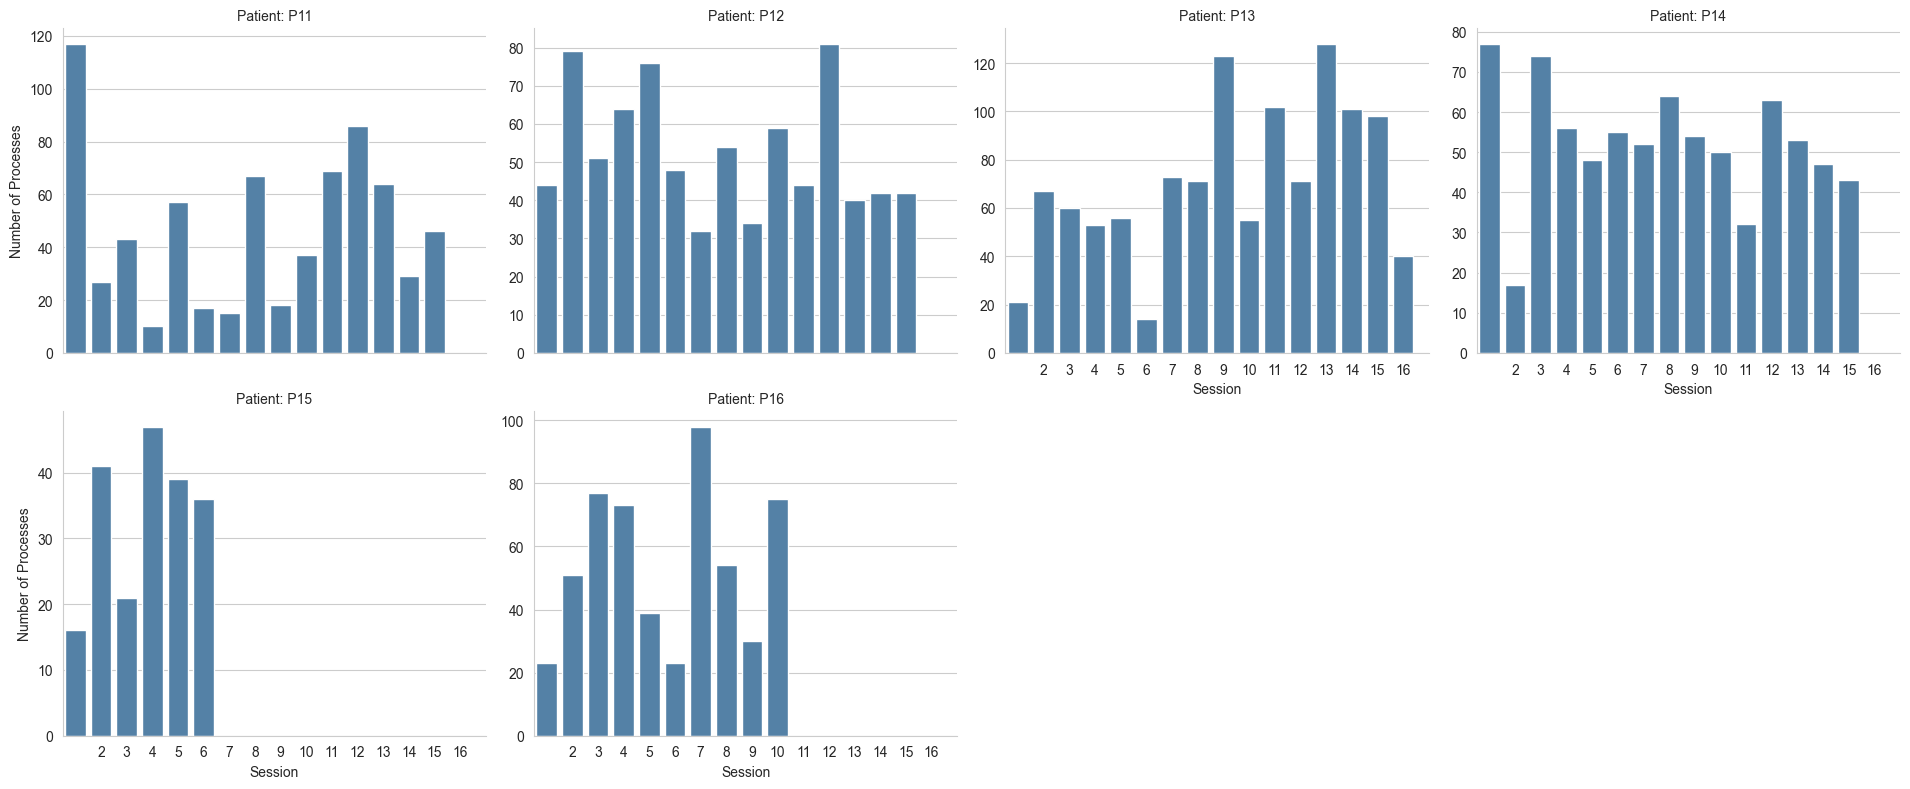

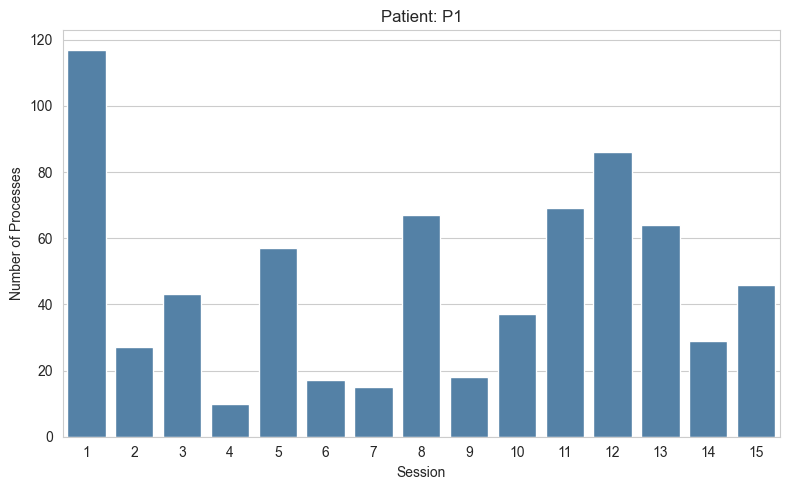

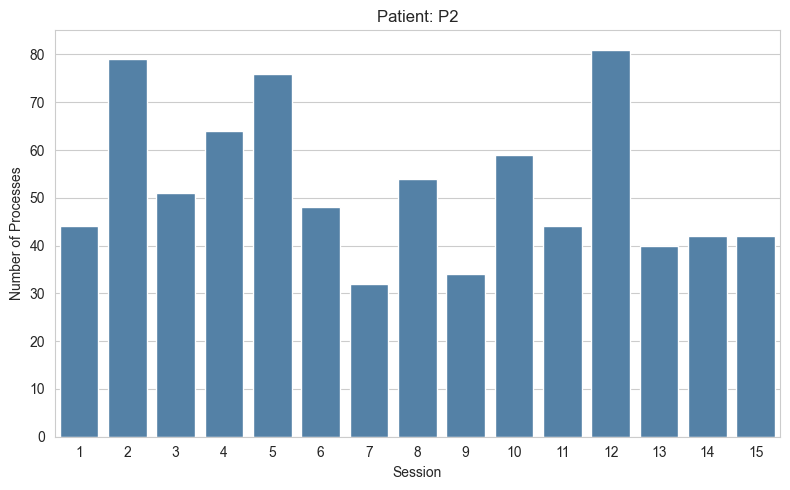

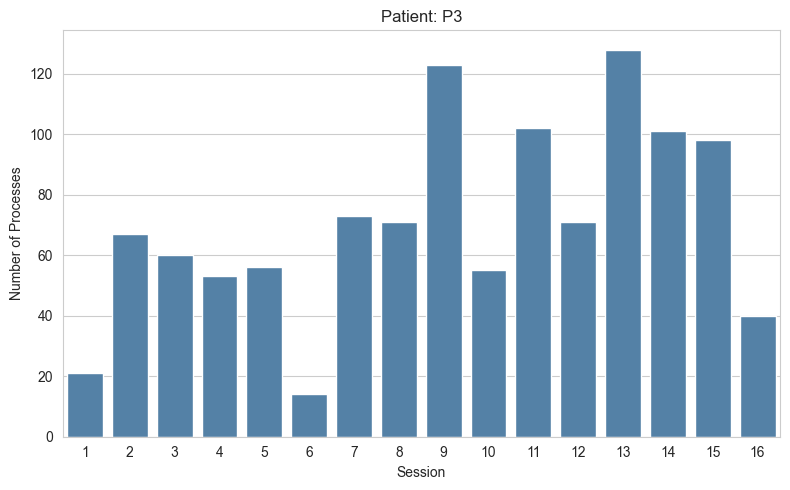

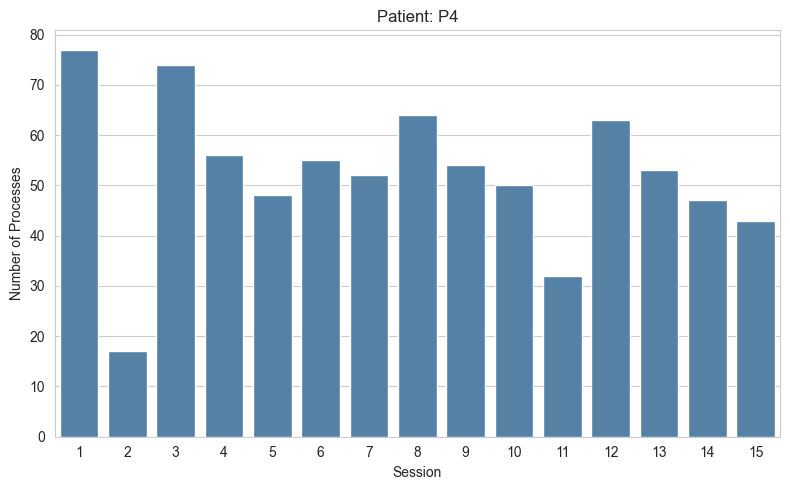

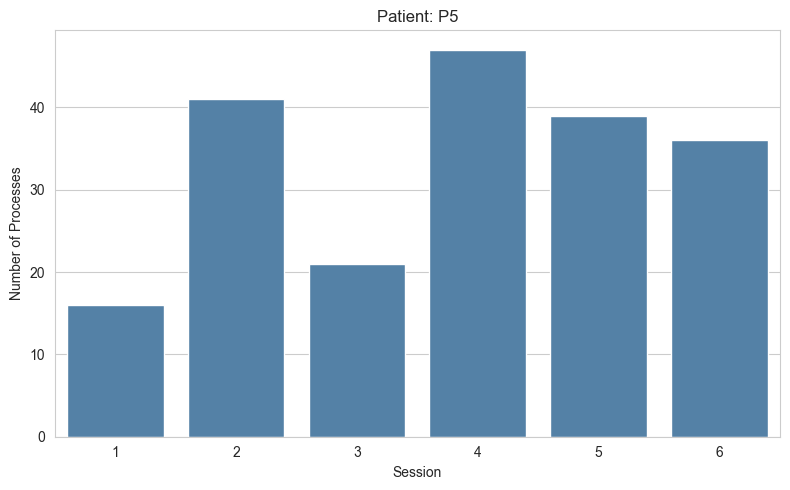

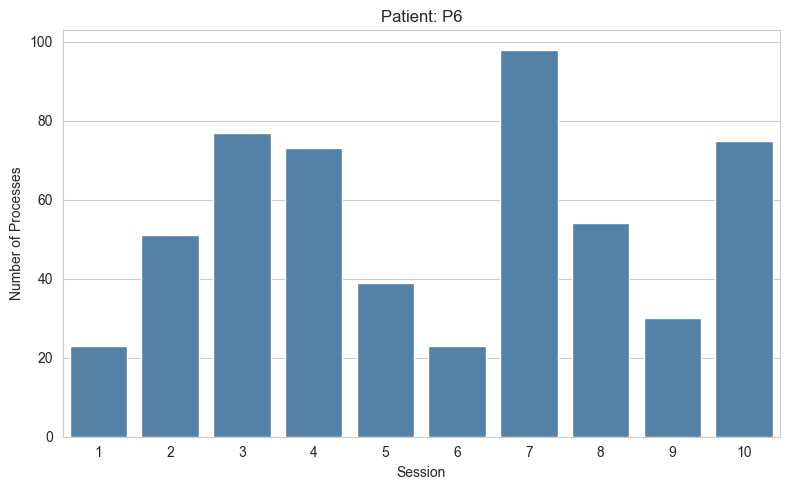

In [19]:
result = compute_processe_plt_all(data)
result = sort_ps(result)
print = result
create_process_plot_for_all(result)
create_process_plot_for_all_sns(result)
create_individual_process_plots(result)

## The Dimensions in each session

In [27]:


# Assuming 'dimension_colors' and 'data_dimension' are already defined
dimension_colors = {
    'Cognition': 'blue',
    'Sense of Self': 'green',
    '(Overt) Behaviour': 'red',
    'Affect': 'purple',
    'Context/Moderators': 'orange',
    'Attention': 'yellow',
    'Biophysiological': 'pink',
    'Motivation': 'tomato' ,
    'Sociocultural': 'limegreen'
}

# Sample list of patients for filtering
p = ['P11', 'P12', 'P13', 'P14', 'P15', 'P16']
data_dimension = count_dimensions_per_session_for_all(data)

# Initialize an empty list to collect rows of output
rows = []

# Iterate over the patients and filter those in 'p'
for patient, details in data_dimension.items():
    if patient in p:  # Use 'in' to filter for patients in list 'p'
        for session, dimensions in details['session_dimension_counts'].items():
            total_processes = details['session_process_counts'].get(session, 0)
            for dimension, count in dimensions.items():
                rows.append({
                    'patient': patient,
                    'session': session,
                    'dimension': dimension,
                    'count': count,
                    'total_processes': total_processes
                })

# Convert the list of rows into a DataFrame
df = pd.DataFrame(rows)

# Set the order of dimensions based on the keys of the dimension_colors dictionary
dimension_order = list(dimension_colors.keys())

# Make 'dimension' a categorical column with the specified order
df['dimension'] = pd.Categorical(df['dimension'], categories=dimension_order, ordered=True)

# Group by 'patient' and 'session' to calculate total processes for each session
df_totals = df.groupby(['patient', 'session'])['count'].sum().reset_index()
df_totals.rename(columns={'count': 'total_count'}, inplace=True)

# Merge the total counts back to the original dataframe
df = pd.merge(df, df_totals, on=['patient', 'session'])

# Calculate percentage by dividing the count of each dimension by the total count per session
df['percentage'] = (df['count'] / df['total_count']) * 100

# Plot with Plotly Express: Facet by patient (rows), session on the x-axis
fig = px.bar(
    df,
    x='session',  # Session on the x-axis
    y='percentage',    # Percentage on the y-axis
    color='dimension',  # Color bars by dimension
    facet_row='patient',  # One plot per patient, stacked vertically
    color_discrete_map=dimension_colors,
    category_orders={'dimension': dimension_order},  # Ensure correct order of dimensions
    title="Percentage of Processes per Patient, Session, and Dimension"
)

# Make the bars stacked and adjust the layout
fig.update_layout(
    barmode='stack',
    height=1200,  # Increase the overall height of the figure to give more room to each subplot
    margin=dict(l=50, r=50, t=50, b=50),  # Adjust margins for more breathing room
)


# Show the plot
fig.show()


TypeError: string indices must be integers, not 'str'

C:\Users\Eugen\AppData\Local\Temp\ipykernel_9268\2734249361.py:4: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



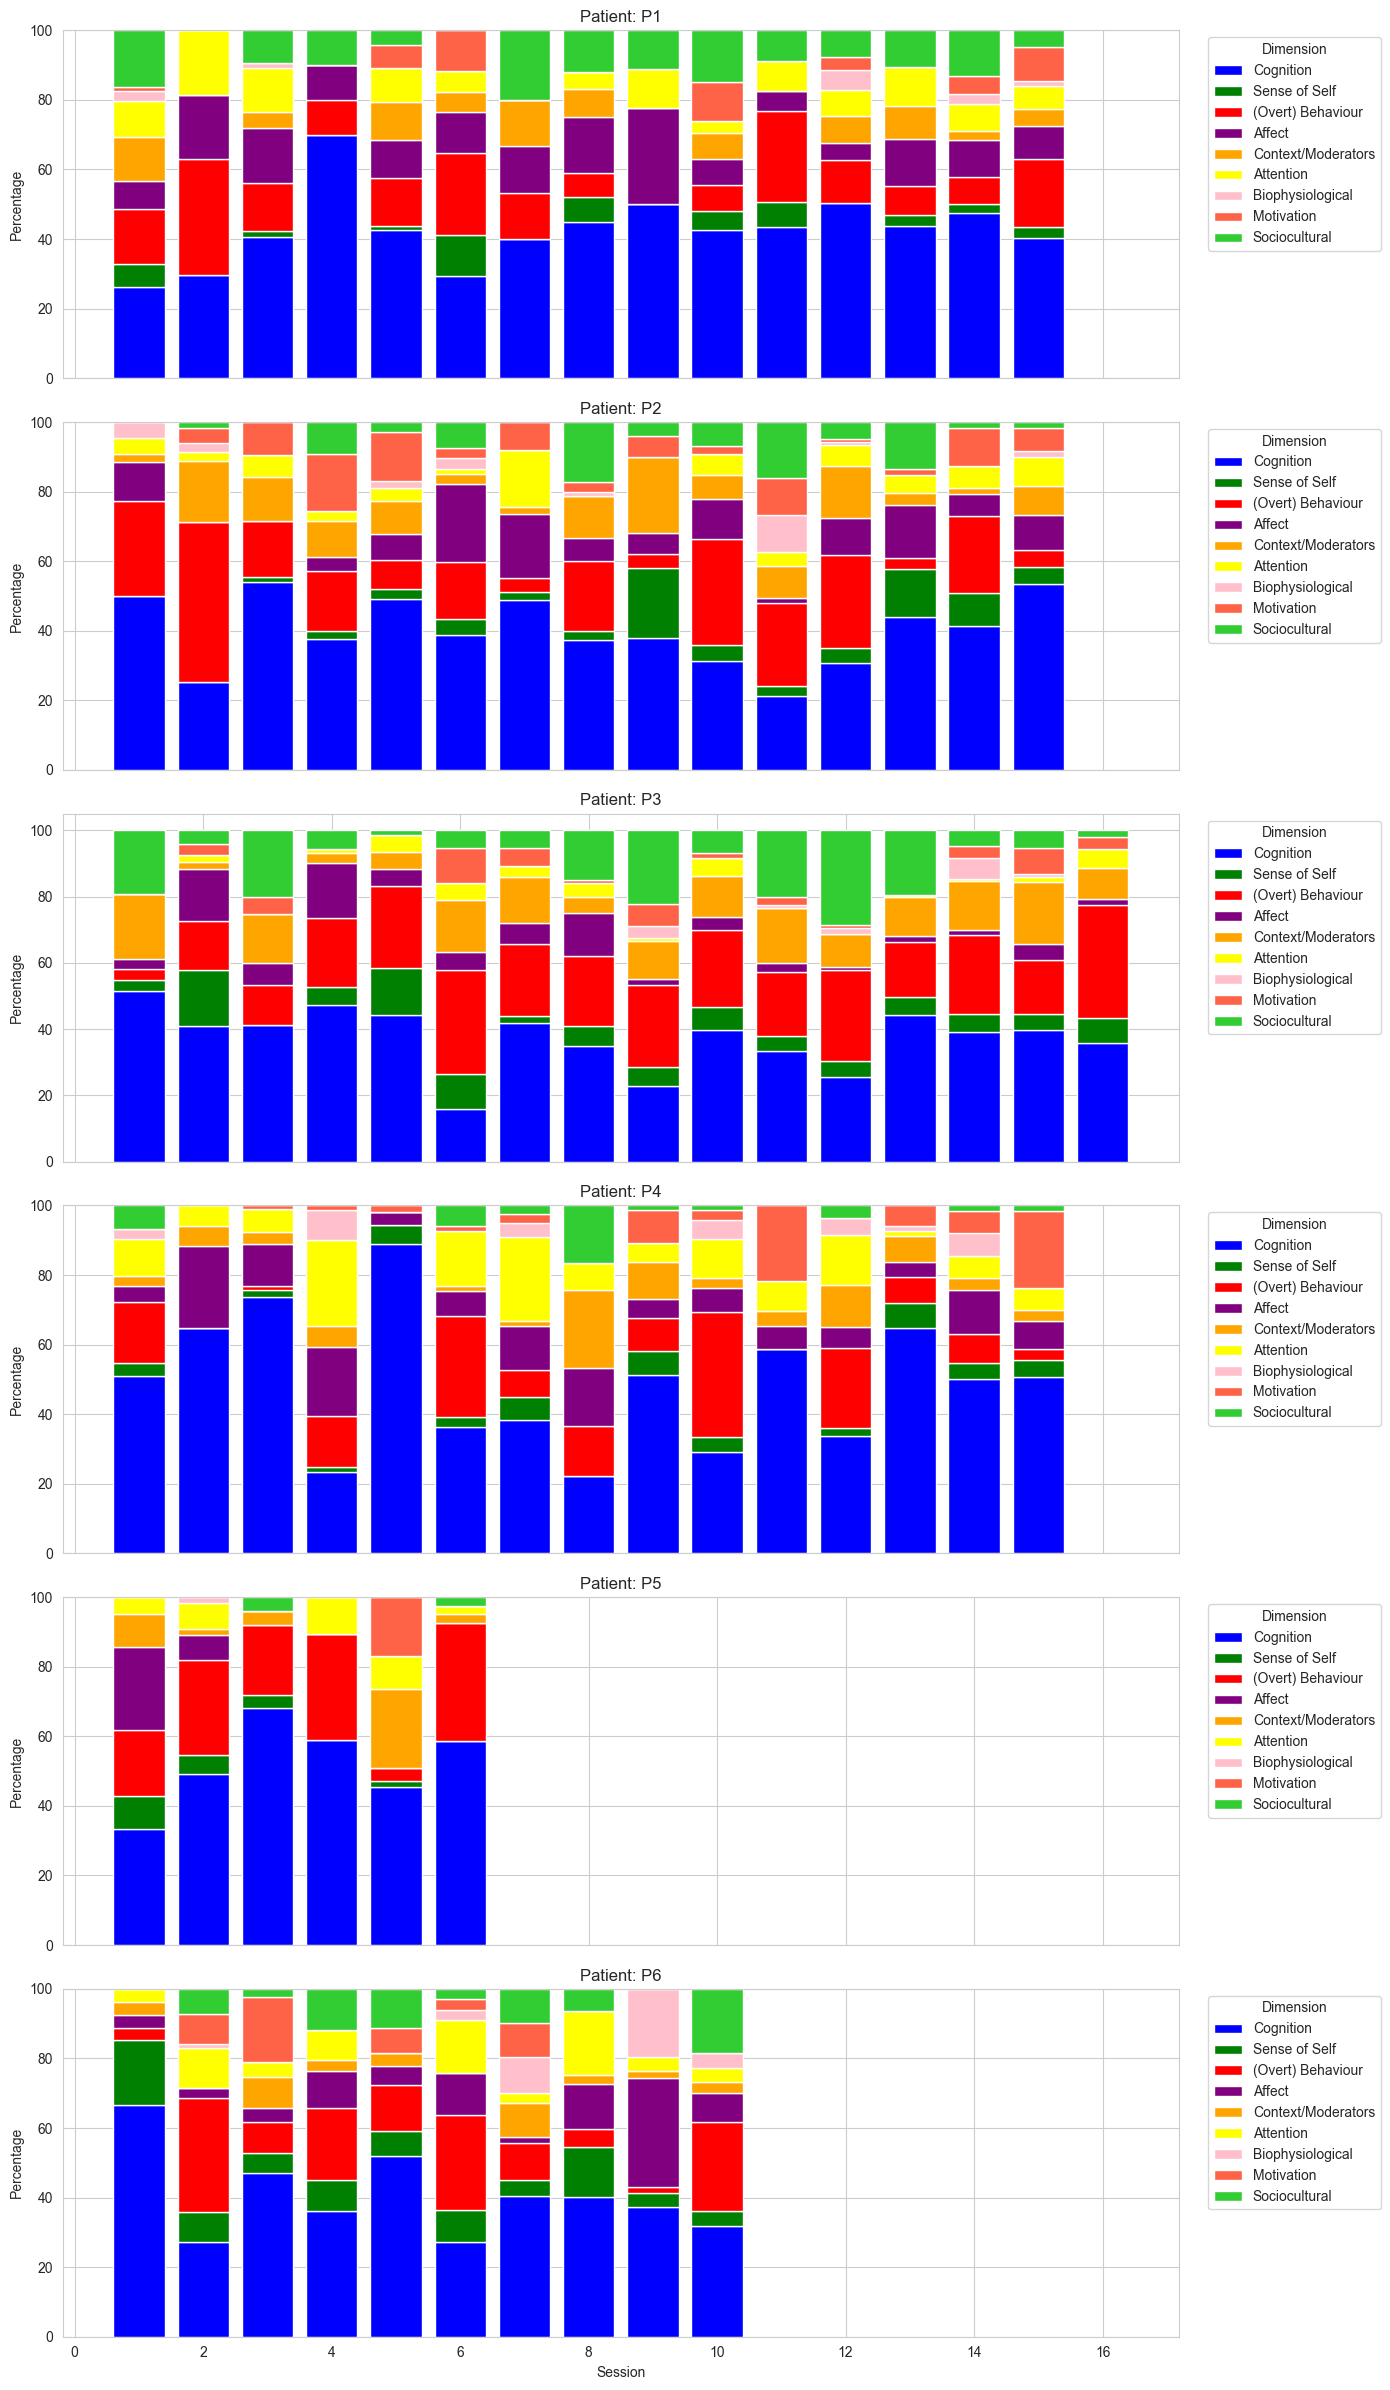

In [24]:
# --- Assume df, dimension_order, and dimension_colors are already defined ---

# Step 1: Pivot using raw counts
pivot_counts = df.pivot_table(
    index=['patient', 'session'],
    columns='dimension',
    values='count',
    aggfunc='sum',
    fill_value=0
).reset_index()

# Step 2: Reorder columns to match dimension order
pivot_counts = pivot_counts[['patient', 'session'] + dimension_order]

id_mapping = {"P11": "P1", "P12": "P2", "P13": "P3", "P14": "P4", "P15": "P5", "P16": "P6"}
pivot_counts['patient'] = pivot_counts['patient'].replace(id_mapping)

# Step 3: Normalize each session's counts to percentages
pivot_counts[dimension_order] = pivot_counts[dimension_order].div(
    pivot_counts[dimension_order].sum(axis=1), axis=0
) * 100

# Step 4: Plot: One subplot per patient
patients = pivot_counts['patient'].unique()
n = len(patients)

fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, 4 * n), sharex=True)

# Handle single-patient case
if n == 1:
    axes = [axes]

# Step 5: Generate plots per patient
for i, patient in enumerate(patients):
    ax = axes[i]
    data = pivot_counts[pivot_counts['patient'] == patient]
    bottom = None
    for dim in dimension_order:
        values = data[dim]
        ax.bar(
            data['session'],
            values,
            bottom=bottom,
            label=dim,
            color=dimension_colors.get(dim, 'gray')
        )
        bottom = values if bottom is None else bottom + values

    ax.set_title(f'Patient: {patient}')
    ax.set_ylabel('Percentage')
    ax.legend(title='Dimension', bbox_to_anchor=(1.02, 1), loc='upper left')

# X-axis label shared
plt.xlabel('Session')
plt.tight_layout()
plt.savefig("patient_session_stacked.pdf")
plt.show()


## Total Number of Processes for each Person and their Dimension

In [30]:
import pandas as pd
import plotly.express as px

# Define dimension colors
dimension_colors = {
    'Cognition': 'blue',
    'Sense of Self': 'green',
    '(Overt) Behaviour': 'red',
    'Affect': 'purple',
    'Context/Moderators': 'orange',
    'Attention': 'yellow',
    'Biophysiological': 'pink',
    'Motivation': 'tomato',
    'Sociocultural': 'limegreen'
}

# Information about the dimension, total process
print(data)
data_dimension = count_dimensions_per_session_for_all(data)

# Initialize an empty list to collect rows of output
rows = []

# Build rows for DataFrame
for patient, details in data_dimension.items():
    for session, dimensions in details['session_dimension_counts'].items():
        total_processes = details['session_process_counts'].get(session, 0)
        for dimension, count in dimensions.items():
            rows.append({
                'patient': patient,
                'session': session,
                'dimension': dimension,
                'count': count,
                'total_processes': total_processes
            })

# Convert the list of rows into a DataFrame
df = pd.DataFrame(rows)

# Set the order of dimensions based on the keys of the dimension_colors dictionary
dimension_order = list(dimension_colors.keys())

# Make 'dimension' a categorical column with the specified order
df['dimension'] = pd.Categorical(df['dimension'], categories=dimension_order, ordered=True)

# Calculate total counts per patient
total_counts = df.groupby('patient')['count'].sum().reset_index()
total_counts.rename(columns={'count': 'total_count'}, inplace=True)

# Merge to get total counts into the original DataFrame
df = pd.merge(df, total_counts, on='patient')

# Calculate the percentage
df['percentage'] = (df['count'] / df['total_count']) * 100

# Group by patient and dimension to prepare for plotting
person_dimension_totals = df.groupby(['patient', 'dimension'])['percentage'].sum().reset_index()

# Plot with Plotly Express: Patient on x-axis, percentage on y-axis, stacked by dimension
fig = px.bar(
    person_dimension_totals,
    x='patient',
    y='percentage',  # Use percentage instead of count
    color='dimension',
    color_discrete_map=dimension_colors,
    category_orders={'dimension': dimension_order},  # Ensure correct order of dimensions
    title="Percentage of Processes per Patient and Dimension"
)

# Set bars to be stacked
fig.update_layout(barmode='stack')


# Show the plot
fig.show()


TypeError: 'dict' object is not callable

C:\Users\Eugen\AppData\Local\Temp\ipykernel_9268\1984741186.py:7: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



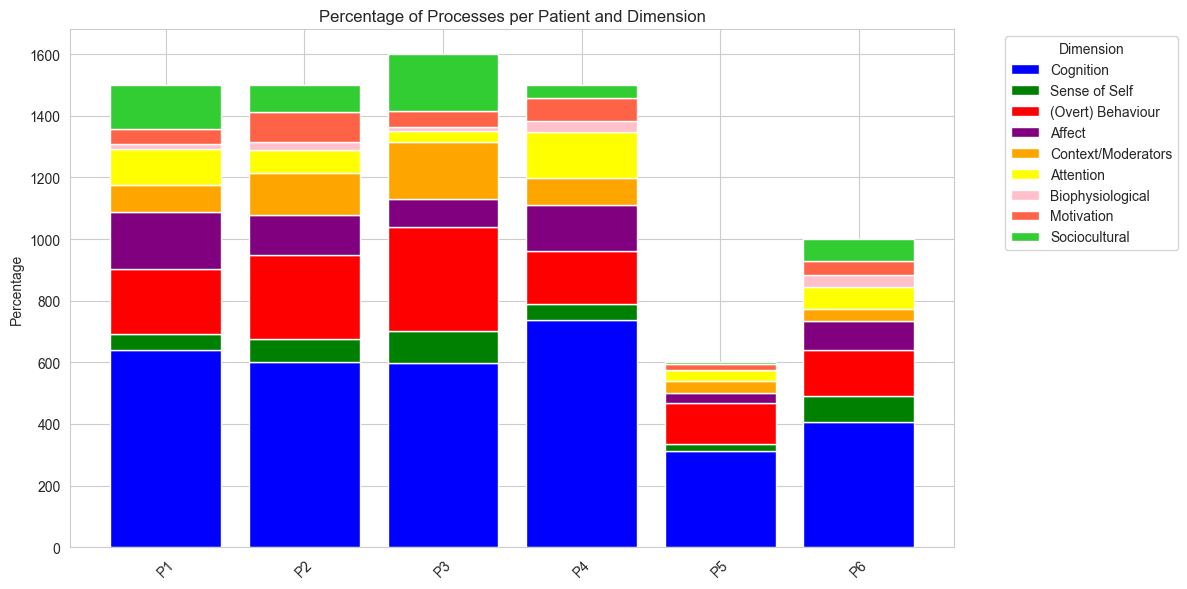

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Assume df, dimension_order, and dimension_colors already defined as in your code

# Pivot the output to get dimensions as columns for stacking
pivot_df = df.pivot_table(
    index='patient',
    columns='dimension',
    values='percentage',
    aggfunc='sum',
    fill_value=0
)

# Reorder columns
pivot_df = pivot_df[dimension_order]

id_mapping = {"P11": "P1", "P12": "P2", "P13": "P3", "P14": "P4", "P15": "P5", "P16": "P6"}
pivot_df.index = pivot_df.index.to_series().replace(id_mapping)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

bottom = None
for dim in dimension_order:
    ax.bar(
        pivot_df.index,
        pivot_df[dim],
        label=dim,
        bottom=bottom,
        color=dimension_colors.get(dim, 'gray')
    )
    bottom = pivot_df[dim] if bottom is None else bottom + pivot_df[dim]

# Labels and title
ax.set_ylabel('Percentage')
ax.set_title('Percentage of Processes per Patient and Dimension')
ax.legend(title='Dimension', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()

# Save to PDF
plt.savefig("total_patient_dimension_percentages.pdf")
plt.show()


# Therapist Sdie

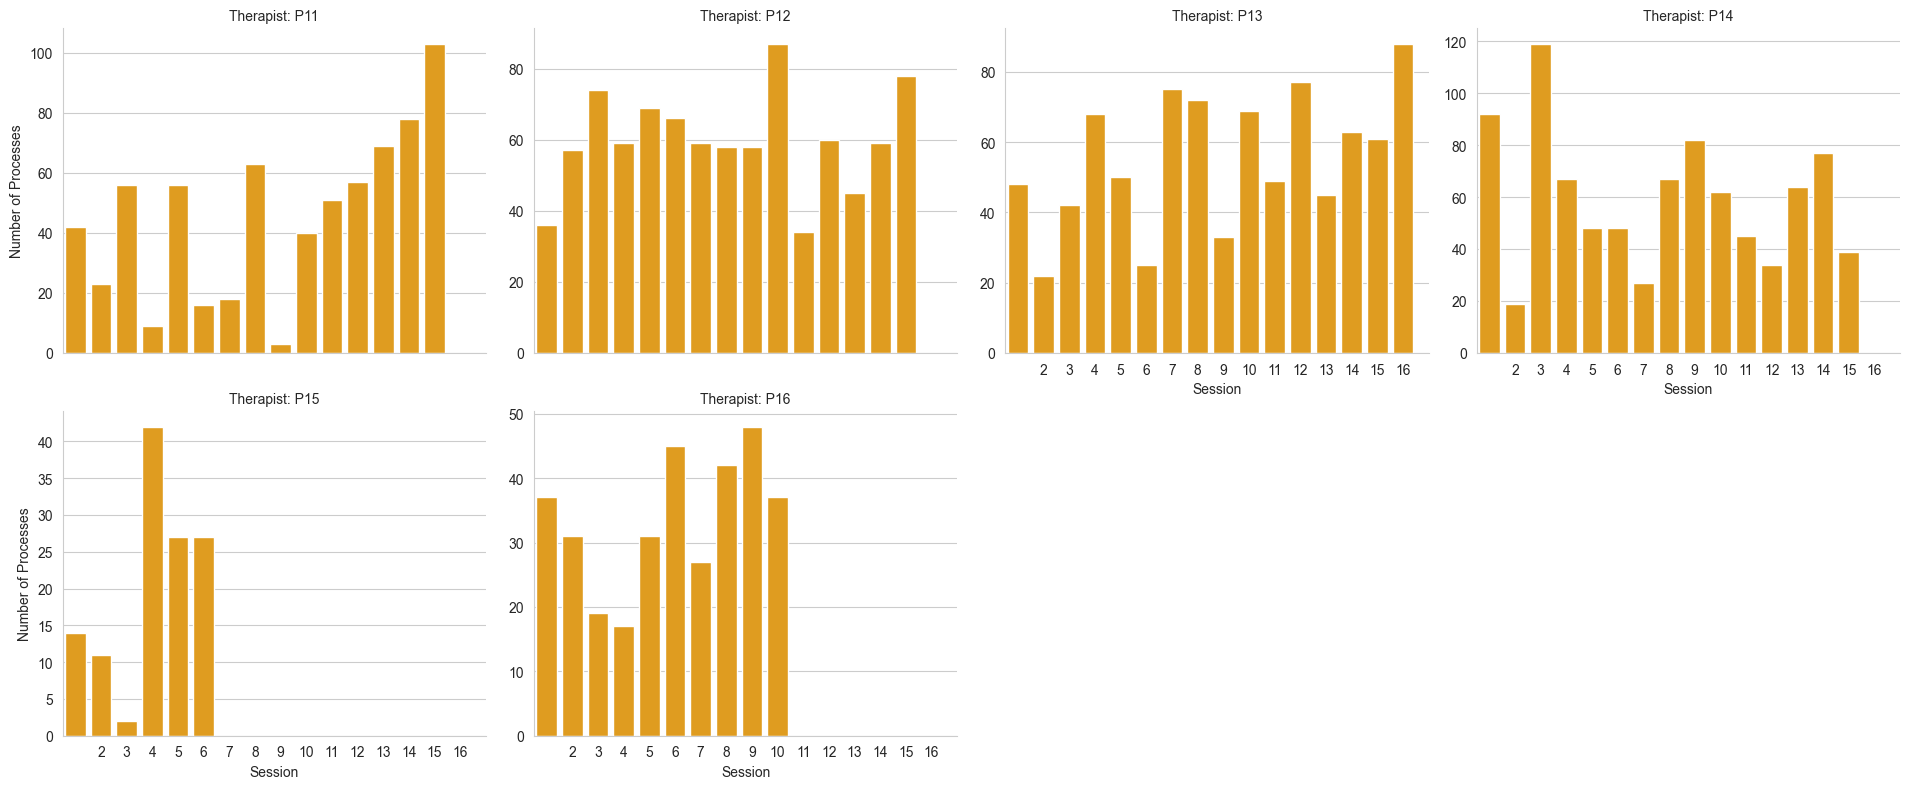

TypeError: list indices must be integers or slices, not str

In [37]:
result = compute_processe_plt_all(data_therapist)
result = sort_ps(result)
create_process_plot_for_all_therapist(result)
create_process_plot_for_all_therapist_sns(result)

In [42]:
import pandas as pd
import plotly.express as px

# Assuming 'dimension_colors' and 'data_dimension' are already defined
dimension_colors = {
    'Cognition': 'blue',
    'Sense of Self': 'green',
    '(Overt) Behaviour': 'red',
    'Affect': 'purple',
    'Context/Moderators': 'orange',
    'Attention': 'yellow',
    'Biophysiological': 'pink',
    'Motivation': 'tomato' ,
    'Sociocultural': 'limegreen'
}

# Information about the dimension, total process
data_dimension = count_dimensions_per_session_for_all(data_therapist)

# Sample list of patients for filtering
p = ['P11', 'P12', 'P13', 'P14', 'P15', 'P16']

# Initialize an empty list to collect rows of output
rows = []

# Iterate over the patients and filter those in 'p'
for therapist, details in data_dimension.items():
    if therapist in p:  # Use 'in' to filter for patients in list 'p'
        for session, dimensions in details['session_dimension_counts'].items():
            total_processes = details['session_process_counts'].get(session, 0)
            for dimension, count in dimensions.items():
                rows.append({
                    'therapist': therapist,
                    'session': session,
                    'dimension': dimension,
                    'count': count,
                    'total_processes': total_processes
                })

# Convert the list of rows into a DataFrame
df = pd.DataFrame(rows)

# Set the order of dimensions based on the keys of the dimension_colors dictionary
dimension_order = list(dimension_colors.keys())

# Make 'dimension' a categorical column with the specified order
df['dimension'] = pd.Categorical(df['dimension'], categories=dimension_order, ordered=True)

# Group by 'therapist' and 'session' to calculate total processes for each session
df_totals = df.groupby(['therapist', 'session'])['count'].sum().reset_index()
df_totals.rename(columns={'count': 'total_count'}, inplace=True)

# Merge the total counts back to the original dataframe
df = pd.merge(df, df_totals, on=['therapist', 'session'])

# Calculate percentage by dividing the count of each dimension by the total count per session
df['percentage'] = (df['count'] / df['total_count']) * 100

# Plot with Plotly Express: Facet by patient (rows), session on the x-axis
fig = px.bar(
    df,
    x='session',  # Session on the x-axis
    y='percentage',    # Percentage on the y-axis
    color='dimension',  # Color bars by dimension
    facet_row='therapist',  # One plot per therapist, stacked vertically
    color_discrete_map=dimension_colors,  # Use specified color map for dimensions
    category_orders={'dimension': dimension_order},  # Ensure correct order of dimensions
    title="Percentage of Processes per Therapist, Session, and Dimension"
)

# Make the bars stacked and adjust the layout
fig.update_layout(
    barmode='stack',
    height=1200,  # Increase the overall height of the figure to give more room to each subplot
    margin=dict(l=50, r=50, t=50, b=50),  # Adjust margins for more breathing room
)


# Show the plot
fig.show()


C:\Users\Eugen\AppData\Local\Temp\ipykernel_8944\378338482.py:7: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



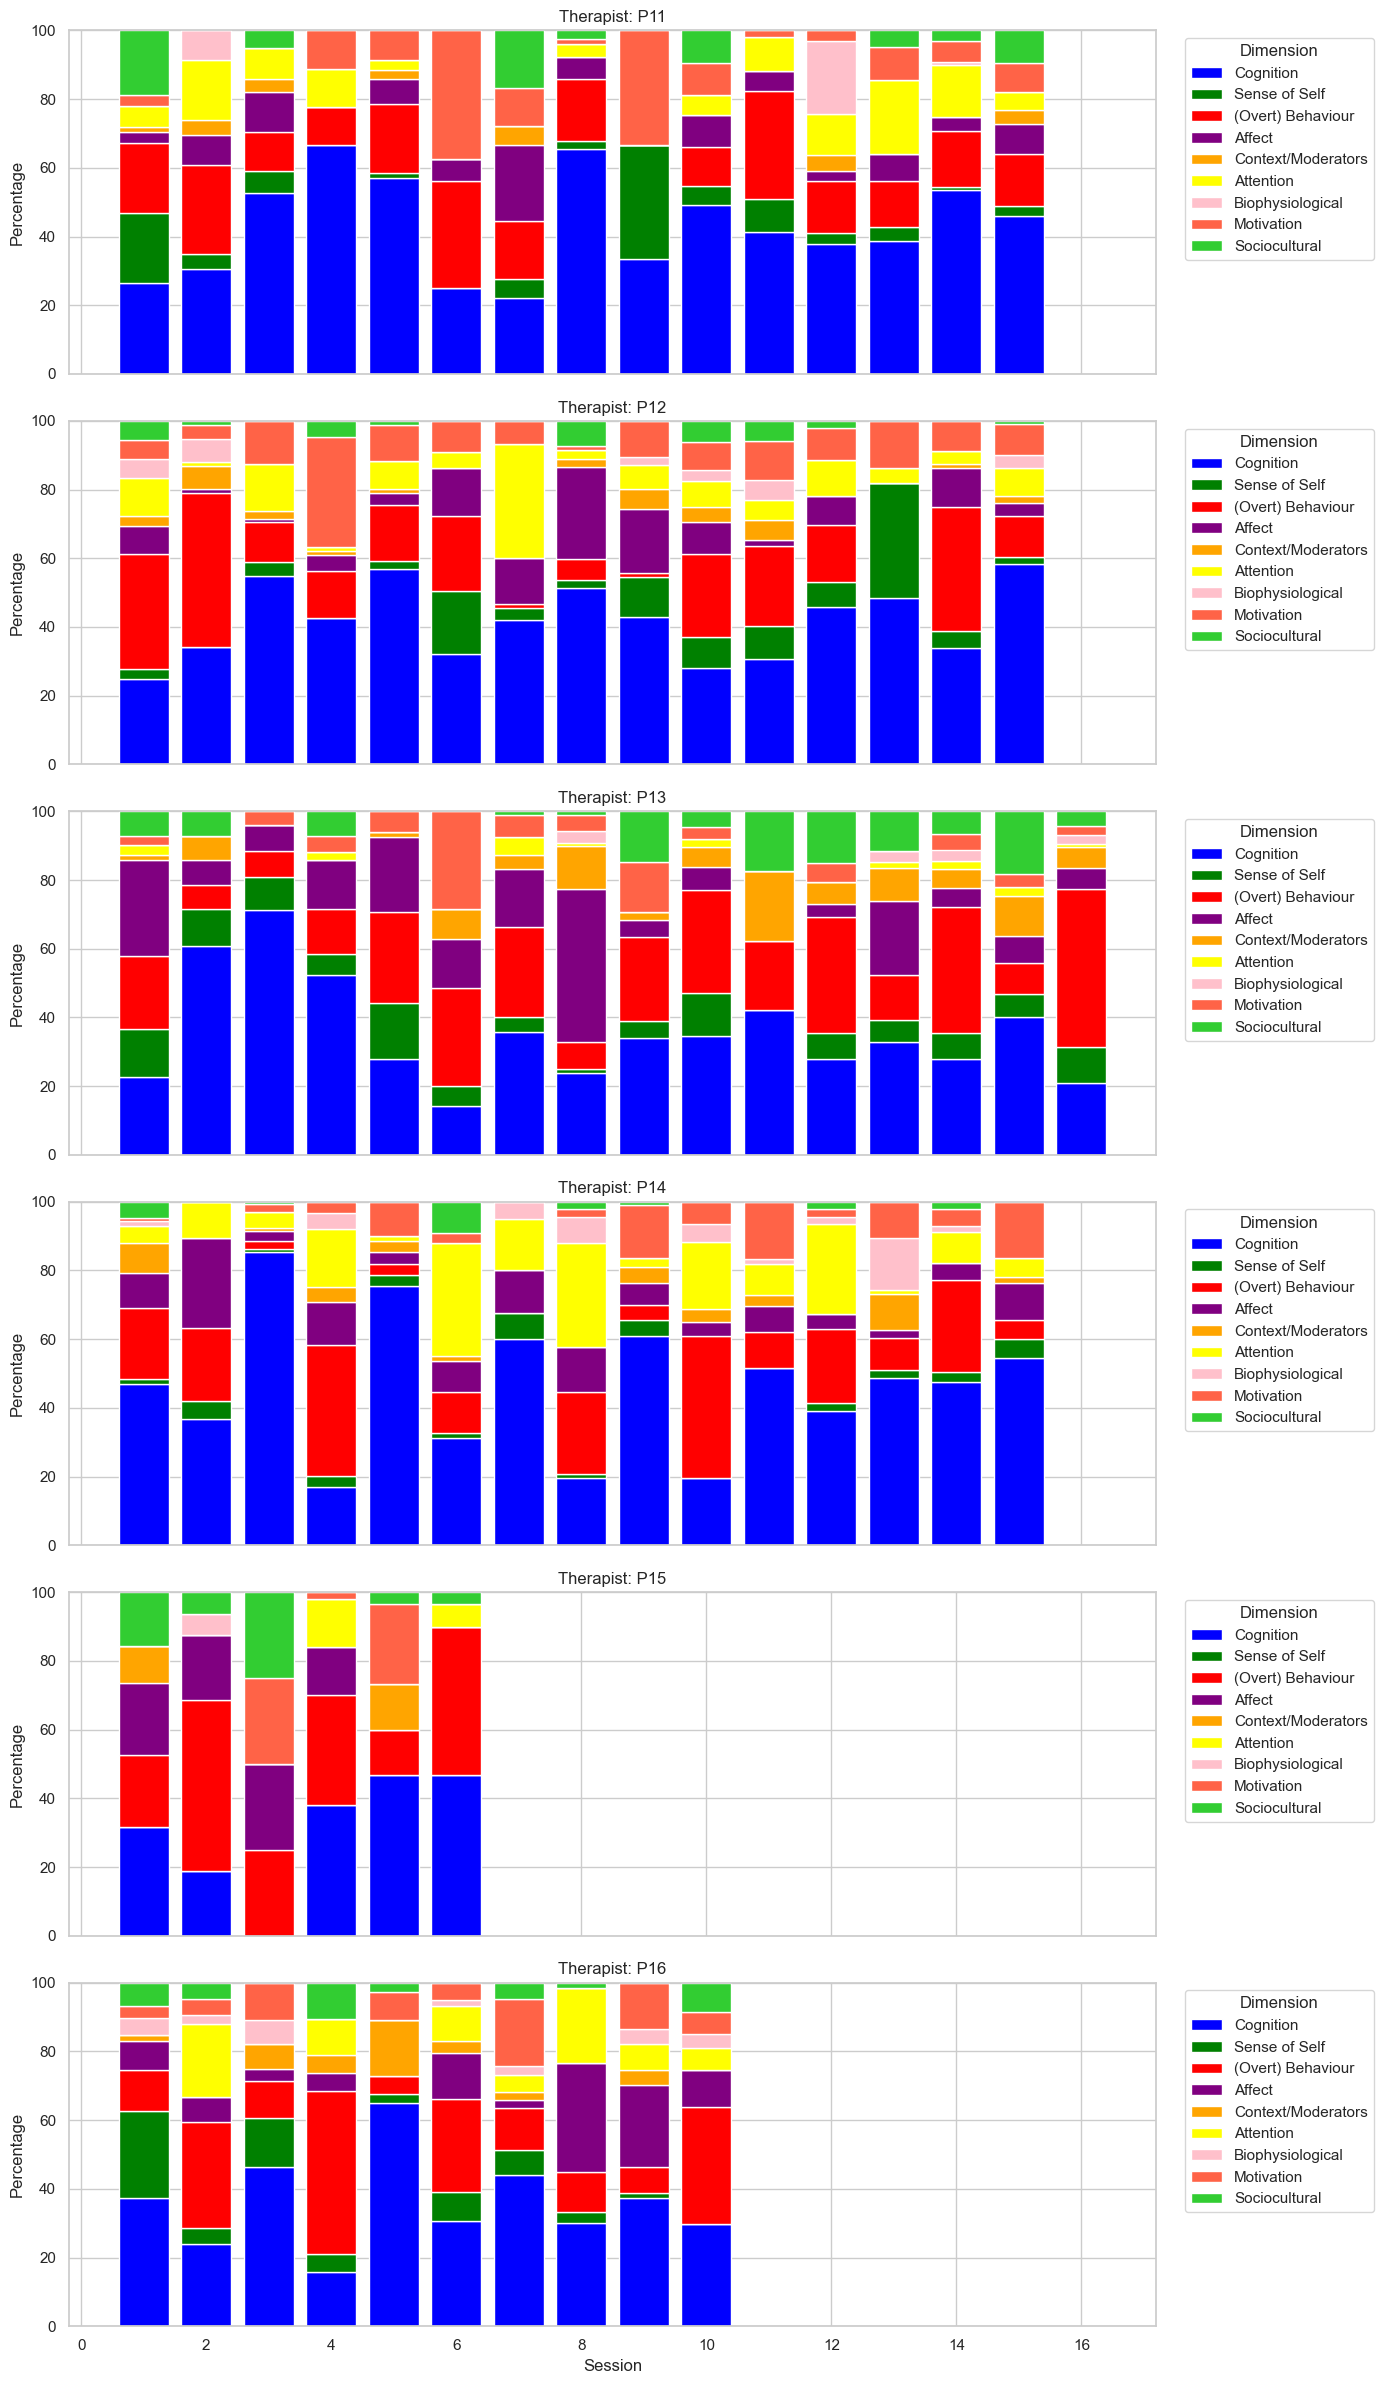

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Assume df, dimension_order, and dimension_colors are already defined ---

# Step 1: Pivot using raw counts
pivot_counts = df.pivot_table(
    index=['therapist', 'session'],
    columns='dimension',
    values='count',
    aggfunc='sum',
    fill_value=0
).reset_index()

# Step 2: Reorder columns
pivot_counts = pivot_counts[['therapist', 'session'] + dimension_order]


# Step 3: Normalize counts to percentages per therapist-session
pivot_counts[dimension_order] = pivot_counts[dimension_order].div(
    pivot_counts[dimension_order].sum(axis=1), axis=0
) * 100

# Step 4: Plot
therapists = pivot_counts['therapist'].unique()
n = len(therapists)

fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, 4 * n), sharex=True)

# Handle single therapist case
if n == 1:
    axes = [axes]

for i, therapist in enumerate(therapists):
    ax = axes[i]
    data = pivot_counts[pivot_counts['therapist'] == therapist]
    bottom = None
    for dim in dimension_order:
        values = data[dim]
        ax.bar(
            data['session'],
            values,
            bottom=bottom,
            label=dim,
            color=dimension_colors.get(dim, 'gray')
        )
        bottom = values if bottom is None else bottom + values

    ax.set_title(f'Therapist: {therapist}')
    ax.set_ylabel('Percentage')
    ax.legend(title='Dimension', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xlabel('Session')
plt.tight_layout()
plt.savefig("session_stacked_by_therapist.pdf")
plt.show()


In [29]:
import pandas as pd
import plotly.express as px

# Assuming 'dimension_colors' and 'data_dimension' are already defined
dimension_colors = {
    'Cognition': 'blue',
    'Sense of Self': 'green',
    '(Overt) Behaviour': 'red',
    'Affect': 'purple',
    'Context/Moderators': 'orange',
    'Attention': 'yellow',
    'Biophysiological': 'pink',
    'Motivation': 'tomato' ,
    'Sociocultural': 'limegreen'
}

# Information about the dimension, total process
data_dimension = count_dimensions_per_session_for_all(data_therapist)


rows = []
# Build rows for DataFrame
for therapist, details in data_dimension.items():
    for session, dimensions in details['session_dimension_counts'].items():
        total_processes = details['session_process_counts'].get(session, 0)
        for dimension, count in dimensions.items():
            rows.append({
                'therapist': therapist,
                'session': session,
                'dimension': dimension,
                'count': count,
                'total_processes': total_processes
            })

df = pd.DataFrame(rows)

# Set the order of dimensions based on the keys of the dimension_colors dictionary
dimension_order = list(dimension_colors.keys())

# Make 'dimension' a categorical column with the specified order
df['dimension'] = pd.Categorical(df['dimension'], categories=dimension_order, ordered=True)

# Calculate total counts per therapist
total_counts = df.groupby('therapist')['count'].sum().reset_index()
total_counts.rename(columns={'count': 'total_count'}, inplace=True)

# Merge to get total counts into the original DataFrame
df = pd.merge(df, total_counts, on='therapist')

# Calculate the percentage
df['percentage'] = (df['count'] / df['total_count']) * 100

# Group by therapist and dimension to prepare for plotting
person_dimension_totals = df.groupby(['therapist', 'dimension'])['percentage'].sum().reset_index()

# Plot with Plotly Express: therapist on x-axis, percentage on y-axis, stacked by dimension
fig = px.bar(
    person_dimension_totals,
    x='therapist',
    y='percentage',  # Use percentage instead of count
    color='dimension',
    color_discrete_map=dimension_colors,
    category_orders={'dimension': dimension_order},  # Ensure correct order of dimensions
    title="Percentage of Processes per Therapist and Dimension"
)

# Set bars to be stacked
fig.update_layout(barmode='stack')


# Show the plot
fig.show()


C:\Users\Eugen\AppData\Local\Temp\ipykernel_8944\240468519.py:54: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



C:\Users\Eugen\AppData\Local\Temp\ipykernel_8944\2655871290.py:8: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



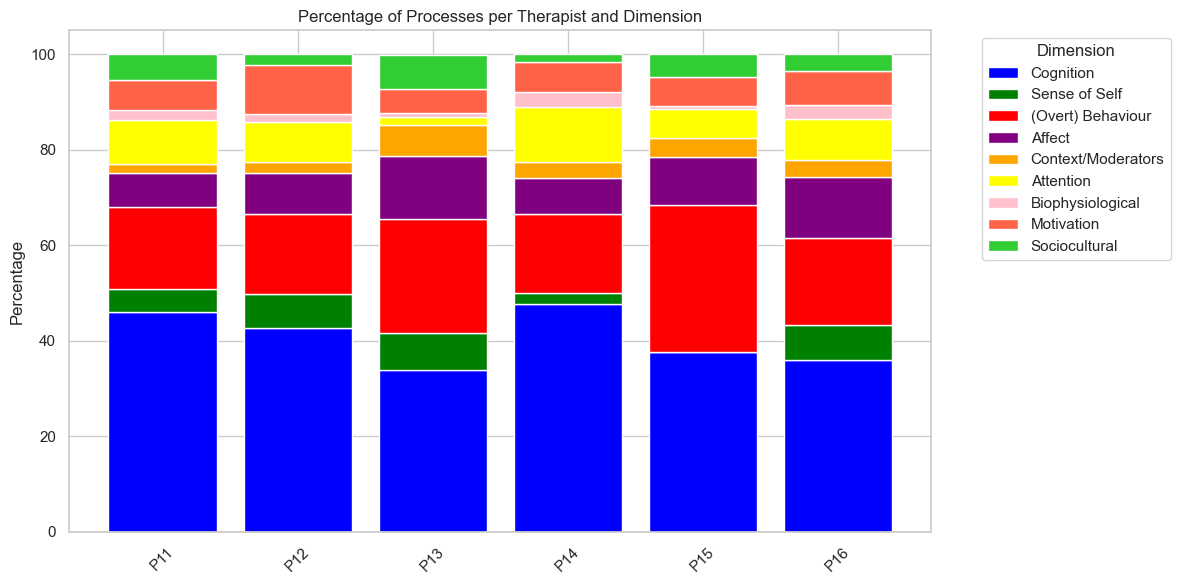

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming dimension_colors and df are already defined as in your original code

# Pivot output to get dimensions as columns for stacked bar chart
pivot_df = df.pivot_table(
    index='therapist',
    columns='dimension',
    values='percentage',
    aggfunc='sum',
    fill_value=0
)

# Ensure column order
pivot_df = pivot_df[dimension_order]

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

bottom = None
for dim in dimension_order:
    ax.bar(
        pivot_df.index,
        pivot_df[dim],
        label=dim,
        bottom=bottom,
        color=dimension_colors.get(dim, 'gray')
    )
    # Update bottom for stacking
    bottom = pivot_df[dim] if bottom is None else bottom + pivot_df[dim]

# Styling
ax.set_ylabel('Percentage')
ax.set_title('Percentage of Processes per Therapist and Dimension')
ax.legend(title='Dimension', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()

# Save as PDF
plt.savefig("therapist_dimensions.pdf")
plt.show()


# Calculating the Utterance, Time and so on

In [9]:
from bs4 import BeautifulSoup
import os
import random

import os
import re
import random
from bs4 import BeautifulSoup

def sessions_as_dict(path, files):
    d = {}
    l = []
    positions = {}
    patients = []

    for session in files:
        try:
            # Validate and extract patient/session IDs using regex
            match = re.match(r'^(P\d+)_S(\d+)_.*\.ttml$', session)
            if not match:
                print(f"[SKIP] Unexpected filename format: {session}")
                continue

            patient_id = match.group(1)
            session_id = int(match.group(2))
            patients.append(patient_id)

            # Read and parse the TTML file safely
            with open(os.path.join(path, session), 'r') as ttml_file:
                soup = BeautifulSoup(ttml_file, 'html.parser')
                body = soup.body
                ttml_utterances = body.find_all('p')

                session_utterances = []
                for ttml_utterance in ttml_utterances:
                    utterance = {
                        "time": ttml_utterance.attrs.get('begin', ''),
                        "speaker": ttml_utterance.attrs.get('ttm:agent', ''),
                        "text": ttml_utterance.text.strip()
                    }
                    l.append(utterance["text"])
                    session_utterances.append(utterance)

                positions[patient_id + str(session_id)] = session_utterances

        except Exception as e:
            print(f"[ERROR] While processing file '{session}': {e}")

    # Remove duplicates and organize output by patient
    patients = list(set(patients))
    for patient_id in patients:
        if patient_id not in d:
            d[patient_id] = []
        for session_id in range(1, 17):
            key = patient_id + str(session_id)
            if key not in positions:
                continue
            d[patient_id].append(positions[key])

    random.shuffle(l)
    return d, l[:int(len(l) * 0.1)]


def count_utterances(sessions):
  L = []
  for entry in sessions:
    patient = entry
    for session_id, session in enumerate(sessions[patient]):
      session_id = session_id + 1
      patient_utterances = 0
      therapist_utterances = 0
      for utterance in session:
          if utterance['speaker'] == 'Therapist':
            therapist_utterances = therapist_utterances + 1
          else:
            patient_utterances = patient_utterances + 1
      therapist_row = {'patient': patient, 'speaker': 'therapist', 'num. of utterances': therapist_utterances, 'session': session_id}
      patient_row = {'patient': patient, 'speaker': 'patient', 'num. of utterances': patient_utterances, 'session': session_id}
      L.append(therapist_row)
      L.append(patient_row)

  return L

In [1]:
import os

mini_sessions = {}
mini_sample_utterances = []
mini_sessions_files = os.listdir('slurm_clustering_clinicly/mini_sessions')
mini_sessions, mini_sample_utterances = sessions_as_dict('slurm_clustering_clinicly/mini_sessions/', mini_sessions_files)

NameError: name 'sessions_as_dict' is not defined

In [12]:
import json
import pandas as pd

def save_to_file(data, filename):
    # Öffnen und Speichern des Dictionaries in einer Datei
    with open(filename, 'w') as file:
        json.dump(data, file, indent=4)

def save_to_excel(data, filename):
    # Liste erstellen, um die Daten zu speichern
    rows = []

    # Iteration über das Dictionary, um es in eine tabellarische Form zu bringen
    for patient_id, sessions in data.items():
        for session_id, session_data in sessions.items():
            rows.append(session_data)

    # Umwandlung in einen pandas DataFrame
    df = pd.DataFrame(rows)

    # Speichern als Excel-Datei
    df.to_excel(filename, index=False)

def process_data(data):
    result = {}
    for entry in data:
        patient_id = entry['patient']
        session_id = entry['session']
        speaker = entry['speaker']
        num_utterances = entry['num. of utterances']

        if patient_id not in result:
            result[patient_id] = {}

        if session_id not in result[patient_id]:
            result[patient_id][session_id] = {
                'patient_id': patient_id,
                'session_id': session_id,
                'number of patient words': 0,
                'number of therapist words': 0,
                '% of patient words': 0.0,
                '% of therapist words': 0.0
            }

        # Füge die Äußerungen des Sprechers hinzu
        if speaker == 'patient':
            result[patient_id][session_id]['number of patient words'] += num_utterances
        elif speaker == 'therapist':
            result[patient_id][session_id]['number of therapist words'] += num_utterances

    # Berechnung der prozentualen Verteilung der Äußerungen für jede Sitzung
    for patient_id, sessions in result.items():
        for session_id, session_data in sessions.items():
            total_utterances = session_data['number of patient words'] + session_data['number of therapist words']
            if total_utterances > 0:
                session_data['% of patient words'] = session_data['number of patient words'] / total_utterances
                session_data['% of therapist words'] = session_data['number of therapist words'] / total_utterances
    return result

utterence_mini_session = count_utterances(mini_sessions)
data_1 = process_data(utterence_mini_session)
print(data_1)
save_to_file(data_1, 'Experiment_data/utterance_mini_session.json')

{'P11': {1: {'patient_id': 'P11', 'session_id': 1, 'number of patient words': 161, 'number of therapist words': 70, '% of patient words': 0.696969696969697, '% of therapist words': 0.30303030303030304}, 2: {'patient_id': 'P11', 'session_id': 2, 'number of patient words': 95, 'number of therapist words': 101, '% of patient words': 0.4846938775510204, '% of therapist words': 0.5153061224489796}, 3: {'patient_id': 'P11', 'session_id': 3, 'number of patient words': 56, 'number of therapist words': 76, '% of patient words': 0.42424242424242425, '% of therapist words': 0.5757575757575758}, 4: {'patient_id': 'P11', 'session_id': 4, 'number of patient words': 65, 'number of therapist words': 90, '% of patient words': 0.41935483870967744, '% of therapist words': 0.5806451612903226}, 5: {'patient_id': 'P11', 'session_id': 5, 'number of patient words': 112, 'number of therapist words': 124, '% of patient words': 0.4745762711864407, '% of therapist words': 0.5254237288135594}, 6: {'patient_id': 'P

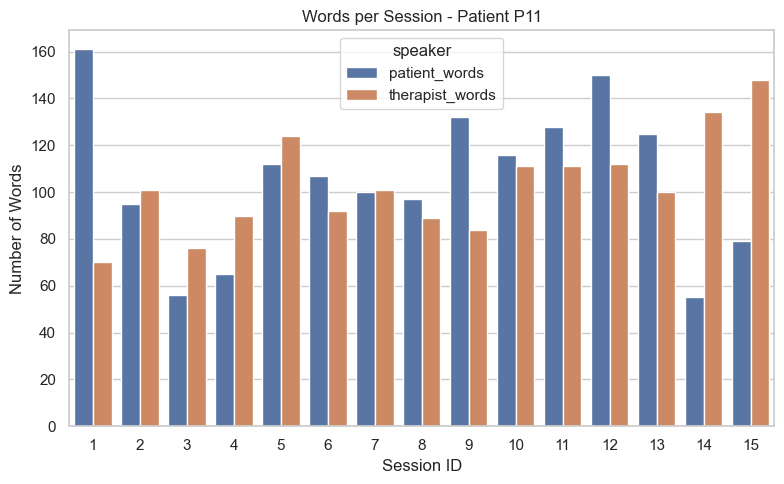

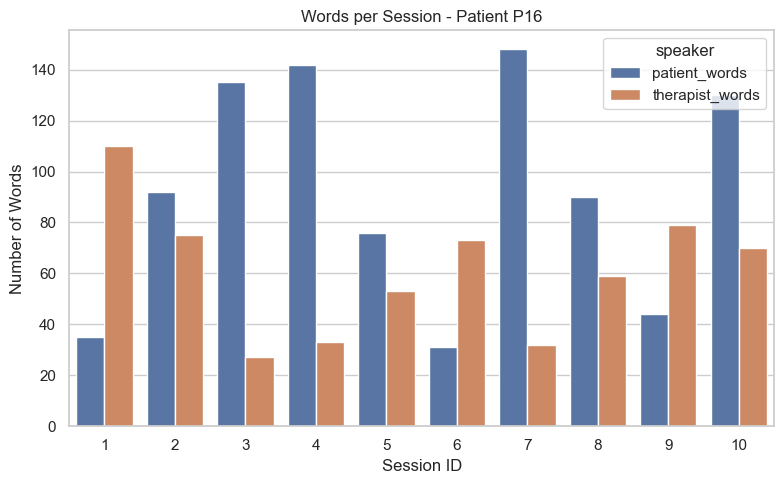

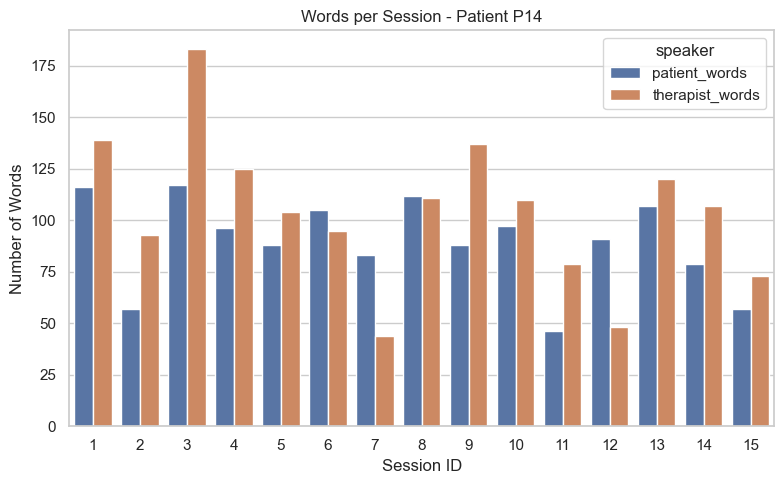

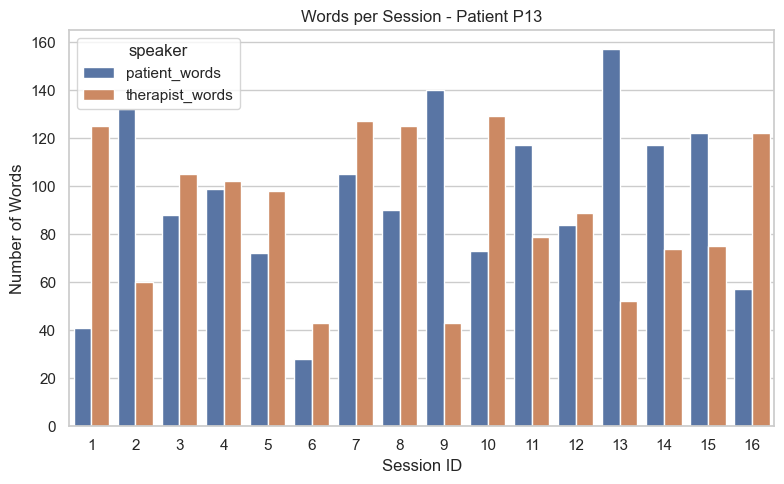

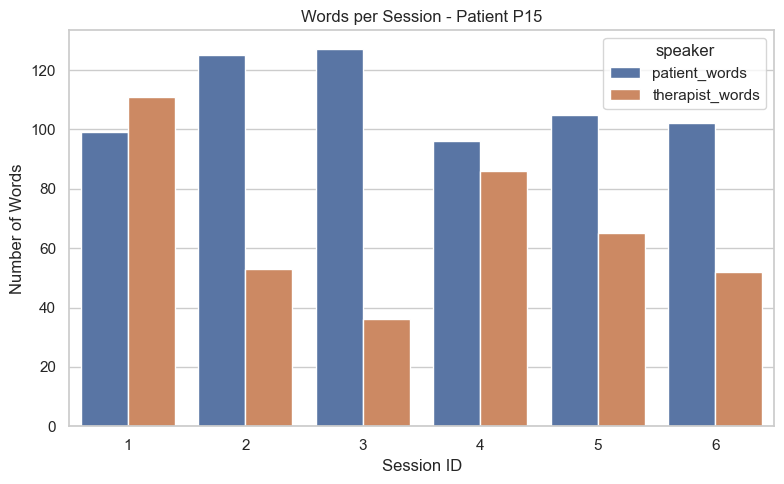

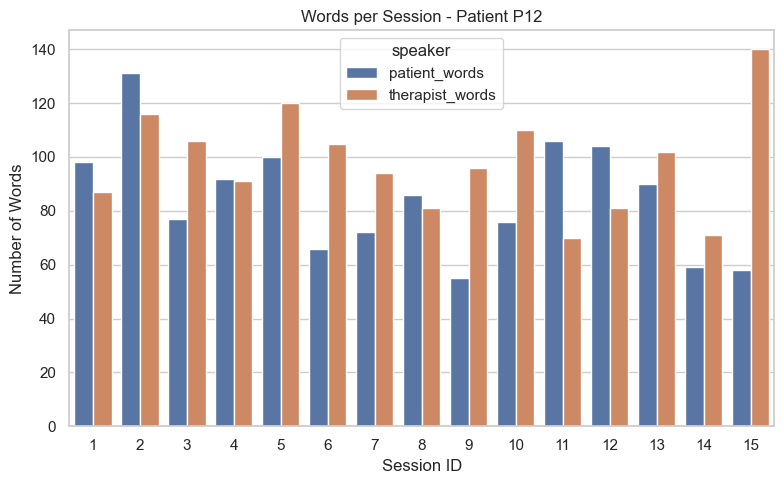

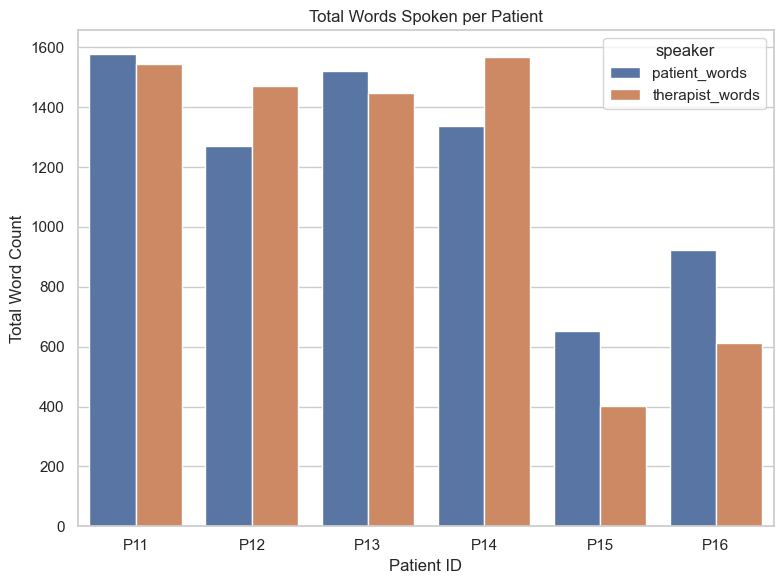

In [5]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load your JSON output ---
with open('Experiment_data/utterance_mini_session.json', 'r') as f:
    data = json.load(f)

# --- Convert to DataFrame ---
rows = []
for patient_id, sessions in data.items():
    for session_id, session_data in sessions.items():
        rows.append({
            'patient_id': patient_id,
            'session_id': session_data['session_id'],
            'patient_words': session_data['number of patient words'],
            'therapist_words': session_data['number of therapist words']
        })

df = pd.DataFrame(rows)

# --- Melt DataFrame for Seaborn compatibility ---
df_long = df.melt(id_vars=['patient_id', 'session_id'],
                  value_vars=['patient_words', 'therapist_words'],
                  var_name='speaker', value_name='word_count')

# --- Plot 1: Per-patient session word counts ---
sns.set(style="whitegrid")
for patient in df_long['patient_id'].unique():
    df_patient = df_long[df_long['patient_id'] == patient]

    plt.figure(figsize=(8, 5))
    sns.barplot(data=df_patient, x="session_id", y="word_count", hue="speaker")
    plt.title(f'Words per Session - Patient {patient}')
    plt.xlabel('Session ID')
    plt.ylabel('Number of Words')
    plt.tight_layout()
     # ✅ Save the figure
    filename = f"Experiment_data/words_per_session_{patient}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures

# --- Plot 2: Total words per patient ---
total_words = df_long.groupby(['patient_id', 'speaker'])['word_count'].sum().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(data=total_words, x='patient_id', y='word_count', hue='speaker')
plt.title('Total Words Spoken per Patient')
plt.xlabel('Patient ID')
plt.ylabel('Total Word Count')
plt.tight_layout()
 # ✅ Save the figure
filename = f"Experiment_data/words_in_total.pdf"
plt.savefig(filename)
plt.show()
plt.close()  # Close to avoid overlapping figures



### Calculating the Number of Words from Patient and Therapist

In [13]:
# go here
def count_words(sessions):
  L = []
  for entry in sessions:
    patient = entry
    for session_id, session in enumerate(sessions[patient]):
      session_id = session_id + 1
      patient_words = 0
      therapist_words = 0
      patient_utterance = 0
      therapist_utterance = 0
      for utterance in session:
          if utterance['speaker'] == 'Therapist':
            therapist_words = therapist_words + len(utterance['text'].split())
            therapist_utterance +=1
          else:
            patient_words = patient_words + len(utterance['text'].split())
            patient_utterance += 1
      therapist_row = {
                'patient': patient,
                'speaker': 'therapist',
                'num. of words': therapist_words,
                'num. of utterances': therapist_utterance,
                'session': session_id
            }
      patient_row = {
                'patient': patient,
                'speaker': 'patient',
                'num. of words': patient_words,
                'num. of utterances': patient_utterance,
                'session': session_id
            }
      L.append(therapist_row)
      L.append(patient_row)

  return L


def process_data_words(data):
    result = {}
    for entry in data:
        patient_id = entry['patient']
        session_id = entry['session']
        speaker = entry['speaker']
        num_words = entry['num. of words']
        num_utterances = entry['num. of utterances']

        if patient_id not in result:
            result[patient_id] = {}

        if session_id not in result[patient_id]:
            result[patient_id][session_id] = {
                'patient_id': patient_id,
                'session_id': session_id,
                'number of patient words': 0,
                'number of therapist words': 0,
                '% of patient words': 0.0,
                '% of therapist words': 0.0,
                'number of patient utterances': 0,
                'number of therapist utterances': 0,
                '% of patient utterances': 0.0,
                '% of therapist utterances': 0.0
            }

        # Füge die Äußerungen des Sprechers hinzu
        if speaker == 'patient':
            result[patient_id][session_id]['number of patient words'] += num_words
            result[patient_id][session_id]['number of patient utterances'] += num_utterances
        elif speaker == 'therapist':
            result[patient_id][session_id]['number of therapist words'] += num_words
            result[patient_id][session_id]['number of therapist utterances'] += num_utterances

    # Berechnung der prozentualen Verteilung der Äußerungen für jede Sitzung
    for patient_id, sessions in result.items():
        for session_id, session_data in sessions.items():
            total_words = session_data['number of patient words'] + session_data['number of therapist words']
            total_utterances = session_data['number of patient utterances'] + session_data['number of therapist utterances']
            if total_words > 0:
                session_data['% of patient words'] = session_data['number of patient words'] / total_words
                session_data['% of therapist words'] = session_data['number of therapist words'] / total_words

            if total_utterances > 0:
                session_data['% of patient utterances'] = session_data['number of patient utterances'] / total_utterances
                session_data['% of therapist utterances'] = session_data['number of therapist utterances'] / total_utterances
    return result


words_mini_session = count_words(mini_sessions)
print(words_mini_session)
data_1 = process_data_words(words_mini_session)
print(data_1)
save_to_excel(data_1, 'Experiment_data/number_words.xlsx')

[{'patient': 'P11', 'speaker': 'therapist', 'num. of words': 603, 'num. of utterances': 70, 'session': 1}, {'patient': 'P11', 'speaker': 'patient', 'num. of words': 1719, 'num. of utterances': 161, 'session': 1}, {'patient': 'P11', 'speaker': 'therapist', 'num. of words': 1059, 'num. of utterances': 101, 'session': 2}, {'patient': 'P11', 'speaker': 'patient', 'num. of words': 833, 'num. of utterances': 95, 'session': 2}, {'patient': 'P11', 'speaker': 'therapist', 'num. of words': 920, 'num. of utterances': 76, 'session': 3}, {'patient': 'P11', 'speaker': 'patient', 'num. of words': 976, 'num. of utterances': 56, 'session': 3}, {'patient': 'P11', 'speaker': 'therapist', 'num. of words': 774, 'num. of utterances': 90, 'session': 4}, {'patient': 'P11', 'speaker': 'patient', 'num. of words': 559, 'num. of utterances': 65, 'session': 4}, {'patient': 'P11', 'speaker': 'therapist', 'num. of words': 1066, 'num. of utterances': 124, 'session': 5}, {'patient': 'P11', 'speaker': 'patient', 'num. 

### Calculate Speak Duration of Patient and Thearpist

In [14]:
print(mini_sessions)

from datetime import datetime, timedelta

def count_time(sessions):
    L = []
    for entry in sessions:
        patient = entry
        for session_id, session in enumerate(sessions[patient]):
            session_id += 1
            patient_time = 0
            therapist_time = 0
            previous_time = None  # This will hold the previous timestamp

            for i, time in enumerate(session):
                # Convert the current time to a datetime object
                current_time = time_to_seconds(time['time'])

                if previous_time:
                    # Calculate the time difference (duration) in seconds
                    duration = (current_time - previous_time).total_seconds()

                    if time['speaker'] == 'Therapist':
                        therapist_time += duration
                    else:
                        patient_time += duration

                # Update the previous timestamp to the current one
                previous_time = current_time

            # Store the results
            therapist_row = {'patient': patient, 'speaker': 'therapist', 'time': therapist_time, 'session': session_id}
            patient_row = {'patient': patient, 'speaker': 'patient', 'time': patient_time, 'session': session_id}
            L.append(therapist_row)
            L.append(patient_row)

    return L

from datetime import datetime

def time_to_seconds(time_str):
    # Convert 'min:seconds:micro_sec' format into a datetime object
    return datetime.strptime(time_str, "%H:%M:%S,%f")

def process_data_time(data):
    result = {}
    for entry in data:
        patient_id = entry['patient']
        session_id = entry['session']
        speaker = entry['speaker']
        num_time = entry['time']

        if patient_id not in result:
            result[patient_id] = {}

        if session_id not in result[patient_id]:
            result[patient_id][session_id] = {
                'patient_id': patient_id,
                'session_id': session_id,
                'speaking duration patient': 0.0,
                'speaking duration of therapist': 0.0,
                'ratio of patient to therapist speaking duration': 0.0
            }

        if speaker == 'patient':
            result[patient_id][session_id]['speaking duration patient'] += num_time
        elif speaker == 'therapist':
            result[patient_id][session_id]['speaking duration of therapist'] += num_time


    for patient_id, sessions in result.items():
        for session_id, session_data in sessions.items():
            # Calculate the ratio of patient to therapist speaking duration
            therapist_duration = session_data['speaking duration of therapist']
            patient_duration = session_data['speaking duration patient']

            if therapist_duration > 0:  # Avoid division by zero
                session_data['ratio of patient to therapist speaking duration'] = patient_duration / therapist_duration
            else:
                session_data['ratio of patient to therapist speaking duration'] = None  # Handle the case when therapist duration is zero

            # Calculate the total speaking time
            total_time = patient_duration + therapist_duration

            # Calculate percentage if total time is greater than zero
            #if total_time > 0:
            #    session_data['% of patient speaking duration'] = patient_duration / total_time
            #    session_data['% of therapist speaking duration'] = therapist_duration / total_time
            #else:
            #    session_data['% of patient speaking duration'] = 0
            #    session_data['% of therapist speaking duration'] = 0

    return result





data_1 = count_time(mini_sessions)
time_mini_session = process_data_time(data_1)
print(time_mini_session)
save_to_excel(time_mini_session, 'Experiment_data/time_mini_session.xlsx')

{'P14': [[{'time': '00:45:00,649', 'speaker': 'Client', 'text': "It's nice that my parents don't have to worry about it and I guess I kind of feed it into that because like."}, {'time': '00:45:06,314', 'speaker': 'Client', 'text': "Yeah, if I was like, I don't know, because it backfired me a little bit because part of it was just that."}, {'time': '00:45:16,302', 'speaker': 'Client', 'text': 'Like, I want to get good grades, partially because it makes me feel good and then also partially because like.'}, {'time': '00:45:22,868', 'speaker': 'Client', 'text': "It makes, I don't know, excuse me, my parents or something like that, but then it's also like."}, {'time': '00:45:30,362', 'speaker': 'Client', 'text': "I've been like, this semester, like, this year has been very different."}, {'time': '00:45:34,643', 'speaker': 'Client', 'text': "I don't know why."}, {'time': '00:45:35,303', 'speaker': 'Client', 'text': "I think it's just because there's a lot of changes that are coming up, but l

## Calculating Utterance and words

   patient_id  session_id  number of patient words  number of therapist words  \
0         P11           1                     1719                        603   
1         P11           2                      833                       1059   
2         P11           3                      976                        920   
3         P11           4                      559                        774   
4         P11           5                     1093                       1066   
..        ...         ...                      ...                        ...   
72        P16           6                      274                        601   
73        P16           7                     1621                        356   
74        P16           8                      723                        585   
75        P16           9                      337                        725   
76        P16          10                     1128                        821   

    % of patient words  % o

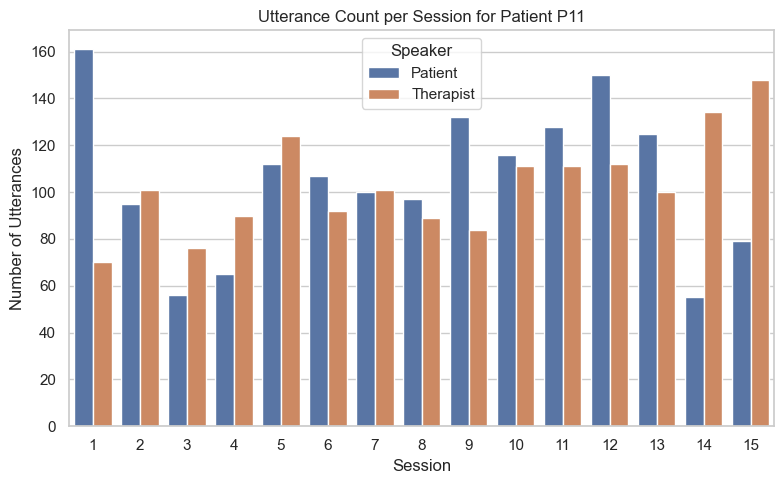

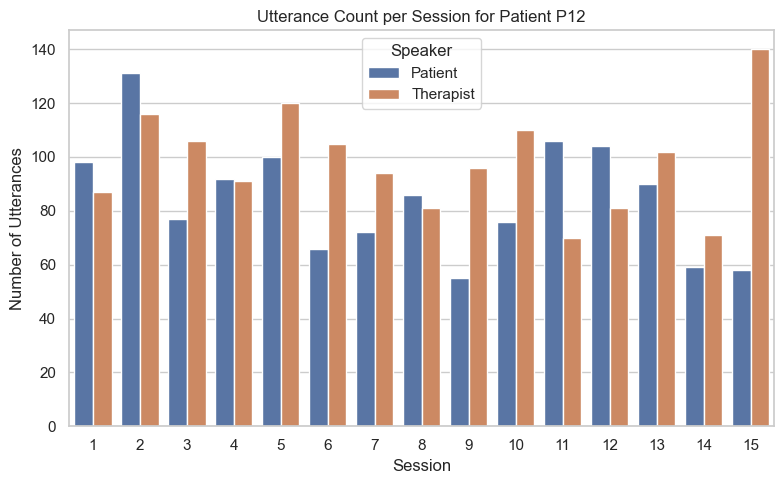

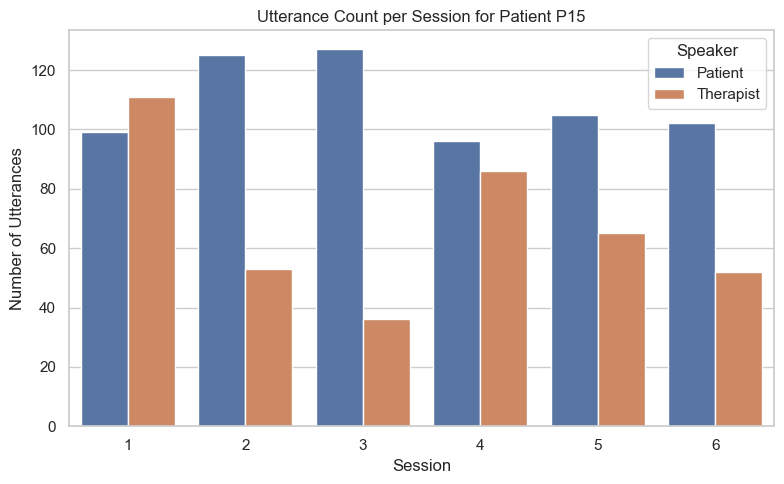

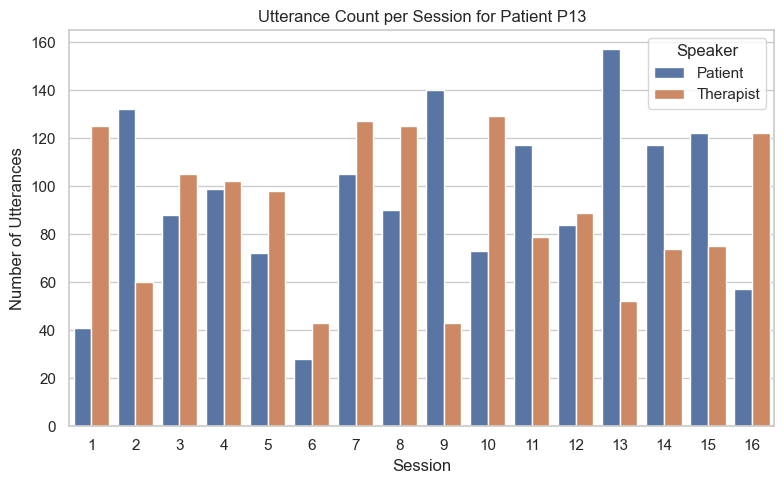

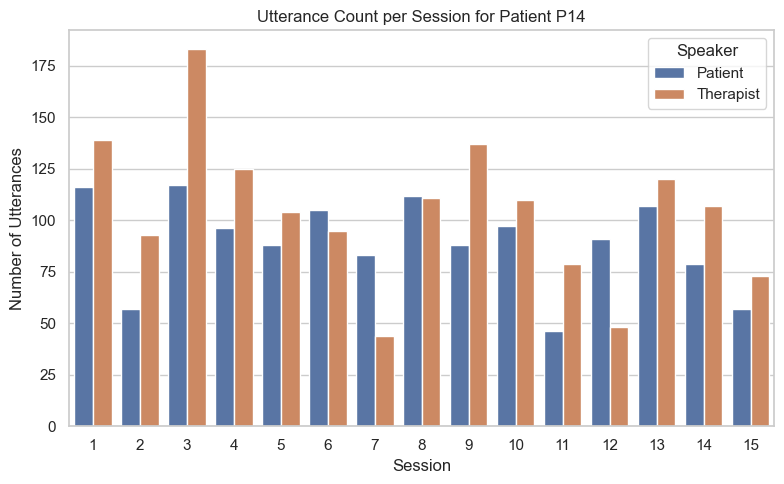

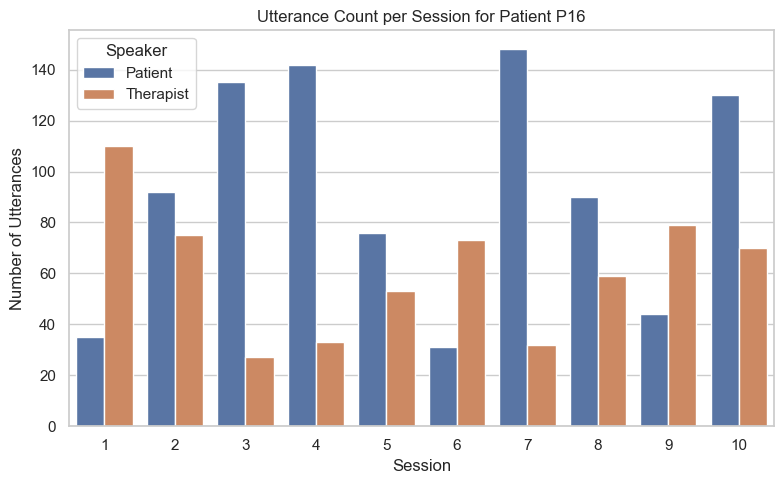

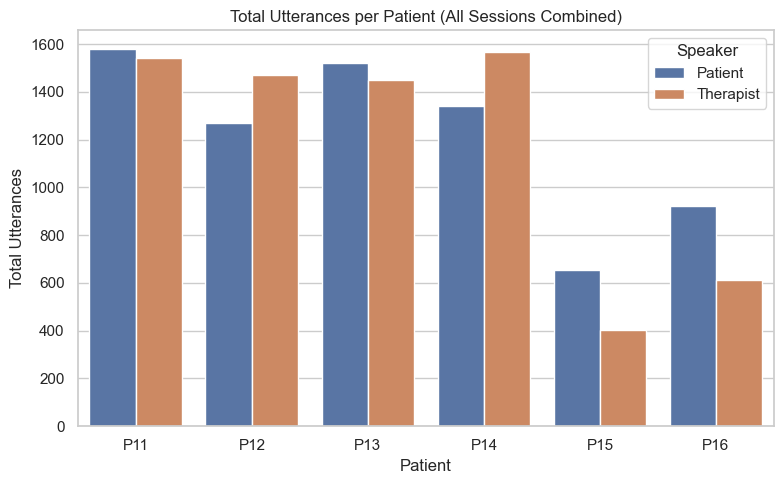

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def flatten_processed_data(data):
    flat_data = []
    for patient_sessions in data.values():
        for session in patient_sessions.values():
            flat_data.append(session)
    return pd.DataFrame(flat_data)

df = flatten_processed_data(data_1)
print(df)

sns.set(style="whitegrid")

for patient_id in df['patient_id'].unique():
    patient_df = df[df['patient_id'] == patient_id]

    # Prepare output for seaborn
    melted_df = patient_df.melt(
        id_vars='session_id',
        value_vars=['number of patient utterances', 'number of therapist utterances'],
        var_name='speaker', value_name='utterances'
    )

    # Make speaker names consistent
    melted_df['speaker'] = melted_df['speaker'].replace({
        'number of patient utterances': 'Patient',
        'number of therapist utterances': 'Therapist'
    })

    # Plot
    plt.figure(figsize=(8, 5))
    sns.barplot(data=melted_df, x='session_id', y='utterances', hue='speaker')
    plt.title(f"Utterance Count per Session for Patient {patient_id}")
    plt.xlabel("Session")
    plt.ylabel("Number of Utterances")
    plt.legend(title="Speaker")
    plt.tight_layout()
     # ✅ Save the figure
    filename = f"utterance_per_session_{patient_id}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures
# Aggregate across all sessions
agg = df.groupby('patient_id')[['number of patient utterances', 'number of therapist utterances']].sum().reset_index()

# Melt for plotting
agg_melted = agg.melt(
    id_vars='patient_id',
    value_vars=['number of patient utterances', 'number of therapist utterances'],
    var_name='speaker', value_name='utterances'
)

# Consistent speaker names
agg_melted['speaker'] = agg_melted['speaker'].replace({
    'number of patient utterances': 'Patient',
    'number of therapist utterances': 'Therapist'
})

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=agg_melted, x='patient_id', y='utterances', hue='speaker')
plt.title("Total Utterances per Patient (All Sessions Combined)")
plt.xlabel("Patient")
plt.ylabel("Total Utterances")
plt.legend(title="Speaker")
plt.tight_layout()
filename = f"Experiment_data/utterance_in_total.pdf"
plt.savefig(filename)
plt.show()
plt.close()  # Close to avoid overlapping figures



   patient_id  session_id  number of patient words  number of therapist words  \
0         P11           1                     1719                        603   
1         P11           2                      833                       1059   
2         P11           3                      976                        920   
3         P11           4                      559                        774   
4         P11           5                     1093                       1066   
..        ...         ...                      ...                        ...   
72        P16           6                      274                        601   
73        P16           7                     1621                        356   
74        P16           8                      723                        585   
75        P16           9                      337                        725   
76        P16          10                     1128                        821   

    % of patient words  % o

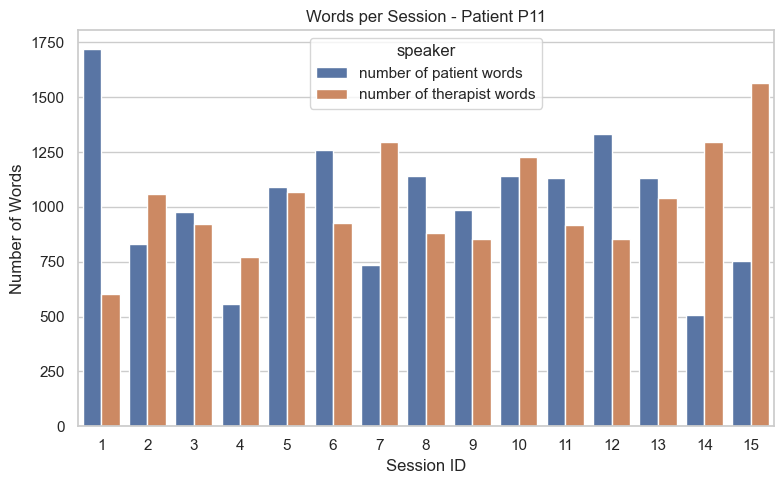

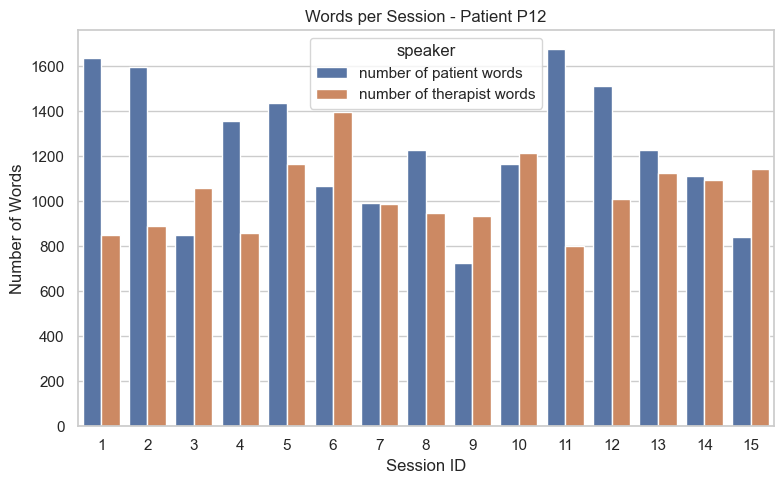

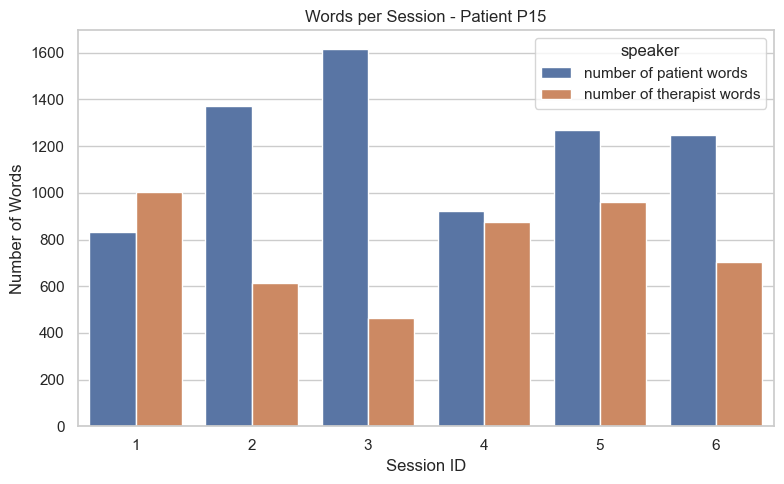

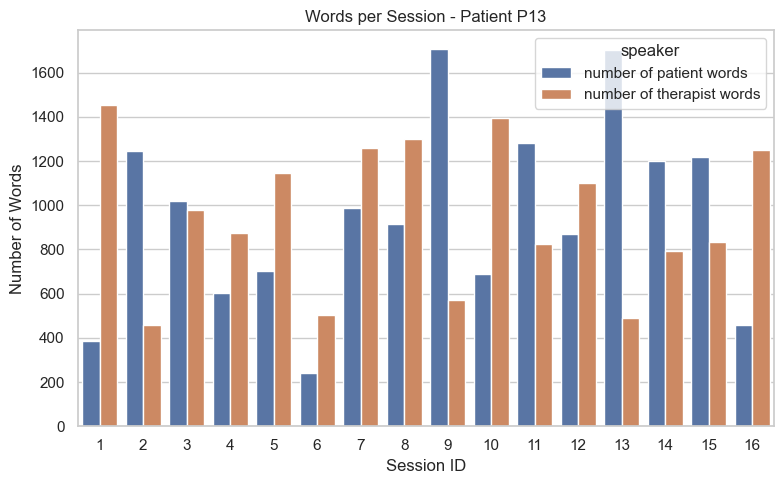

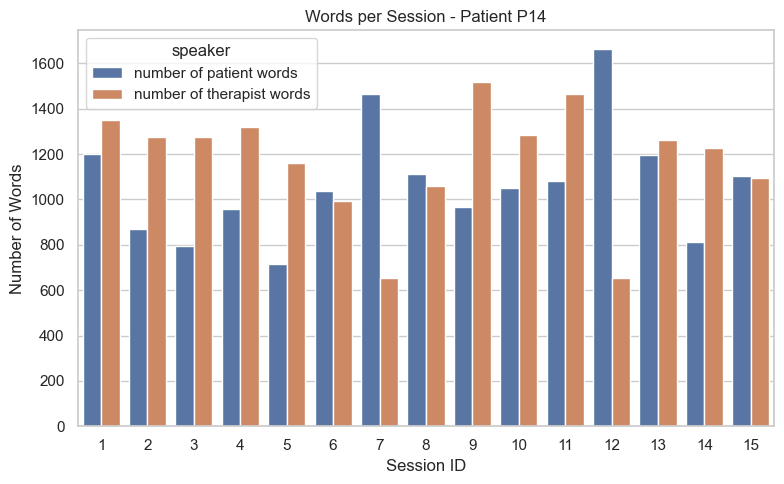

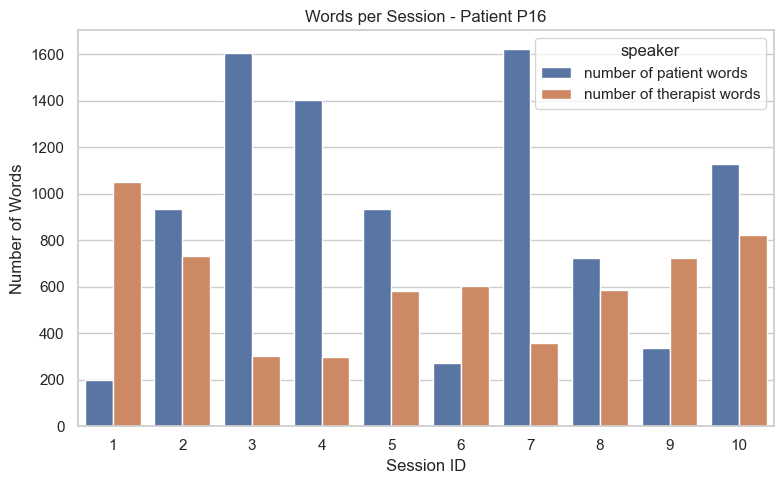

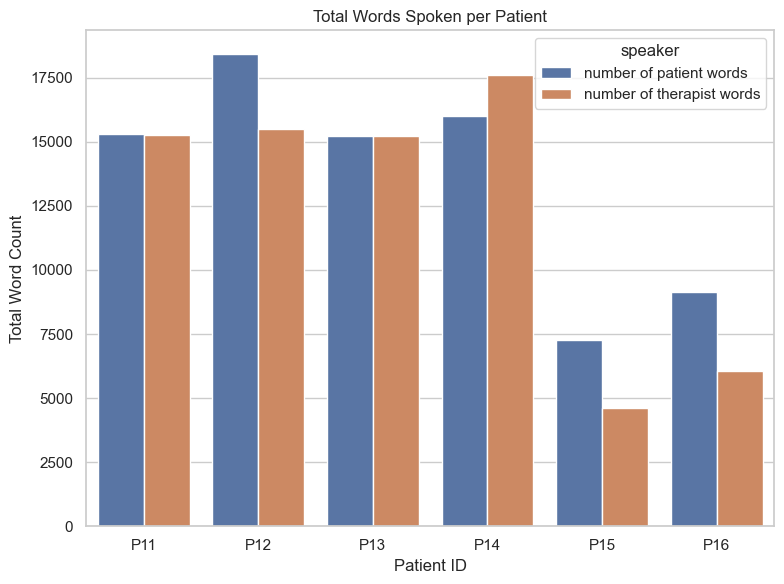

In [18]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load your JSON output ---
with open('utterance_mini_session.json', 'r') as f:
    data = json.load(f)

df = flatten_processed_data(data_1)
print(df)

# --- Melt DataFrame for Seaborn compatibility ---
df_long = df.melt(id_vars=['patient_id', 'session_id'],
                  value_vars=['number of patient words', 'number of therapist words'],
                  var_name='speaker', value_name='word_count')

# --- Plot 1: Per-patient session word counts ---
sns.set(style="whitegrid")
for patient in df_long['patient_id'].unique():
    df_patient = df_long[df_long['patient_id'] == patient]

    plt.figure(figsize=(8, 5))
    sns.barplot(data=df_patient, x="session_id", y="word_count", hue="speaker")
    plt.title(f'Words per Session - Patient {patient}')
    plt.xlabel('Session ID')
    plt.ylabel('Number of Words')
    plt.tight_layout()
     # ✅ Save the figure
    filename = f"Experiment_data/words_per_session_{patient}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures

# --- Plot 2: Total words per patient ---
total_words = df_long.groupby(['patient_id', 'speaker'])['word_count'].sum().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(data=total_words, x='patient_id', y='word_count', hue='speaker')
plt.title('Total Words Spoken per Patient')
plt.xlabel('Patient ID')
plt.ylabel('Total Word Count')
plt.tight_layout()
 # ✅ Save the figure
filename = f"Experiment_data/words_in_total.pdf"
plt.savefig(filename)
plt.show()
plt.close()  # Close to avoid overlapping figures



### Calculate Numbe rof Processes of Patient and Thearpist

In [15]:
result_patient = compute_processe_plt_all(data)
result_patient = sort_ps(result_patient)
print(result_patient)
result_therapist = compute_processe_plt_all(data_therapist)
result_therapist = sort_ps(result_therapist)
print(result_therapist)

def process_patient_and_therapist_data(patient_data, therapist_data):
    result = []

    # Process the patient output
    for patient_id, patient_info in patient_data.items():
        session_counts = patient_info['session_counts']

        # Initialize the results for the patient
        for session_id, patient_duration in session_counts.items():
            # Create an entry for each session
            result_entry = {
                'patient id': patient_id,
                'session id': session_id,
                'number of patient processes': patient_duration,
                'number of therapist processes': 0,  # Placeholder for therapist duration
                '% patient processes': 0.0,  # Placeholder for percentage
                '% therapist processes': 0.0,  # Placeholder for percentage
            }
            result.append(result_entry)

    # Process the therapist output
    for therapist_id, therapist_info in therapist_data.items():
        session_counts = therapist_info['session_counts']

        for session_id, therapist_duration in session_counts.items():
            # Check if the session ID exists in the patient dataset
            for entry in result:
                if entry['patient id'] == therapist_id and entry['session id'] == session_id:
                    # Update the therapist duration in the session
                    entry['number of therapist processes'] += therapist_duration

    # Calculate the percentages
    for entry in result:
        patient_duration = entry['number of patient processes']
        therapist_duration = entry['number of therapist processes']

        total_duration = patient_duration + therapist_duration
        if total_duration > 0:  # Avoid division by zero
            entry['% patient processes'] = (patient_duration / total_duration) * 100
            entry['% therapist processes'] = (therapist_duration / total_duration) * 100
        else:
            entry['% patient processes'] = 0.0
            entry['% therapist processes'] = 0.0

    return result

# Process the output
result = process_patient_and_therapist_data(result_patient, result_therapist)

# Save the result as an Excel file
df = pd.DataFrame(result)

# Specify the order of columns to match the desired format
df = df[['patient id', 'session id', 'number of patient processes',
         'number of therapist processes', '% patient processes',
         '% therapist processes']]

# Save to Excel file
output_file_path = 'Experiment_data/process_mini_session.xlsx'
df.to_excel(output_file_path, index=False)

{'P11': {'session_counts': {1: 117, 2: 27, 3: 43, 4: 10, 5: 57, 6: 17, 7: 15, 8: 67, 9: 18, 10: 37, 11: 69, 12: 86, 13: 64, 14: 29, 15: 46}, 'total_processes': 702}, 'P12': {'session_counts': {1: 44, 2: 79, 3: 51, 4: 64, 5: 76, 6: 48, 7: 32, 8: 54, 9: 34, 10: 59, 11: 44, 12: 81, 13: 40, 14: 42, 15: 42}, 'total_processes': 790}, 'P13': {'session_counts': {1: 21, 2: 67, 3: 60, 4: 53, 5: 56, 6: 14, 7: 73, 8: 71, 9: 123, 10: 55, 11: 102, 12: 71, 13: 128, 14: 101, 15: 98, 16: 40}, 'total_processes': 1133}, 'P14': {'session_counts': {1: 77, 2: 17, 3: 74, 4: 56, 5: 48, 6: 55, 7: 52, 8: 64, 9: 54, 10: 50, 11: 32, 12: 63, 13: 53, 14: 47, 15: 43}, 'total_processes': 785}, 'P15': {'session_counts': {1: 16, 2: 41, 3: 21, 4: 47, 5: 39, 6: 36}, 'total_processes': 200}, 'P16': {'session_counts': {1: 23, 2: 51, 3: 77, 4: 73, 5: 39, 6: 23, 7: 98, 8: 54, 9: 30, 10: 75}, 'total_processes': 543}}
{'P11': {'session_counts': {1: 42, 2: 23, 3: 56, 4: 9, 5: 56, 6: 16, 7: 18, 8: 63, 9: 3, 10: 40, 11: 51, 12: 5

### Calculate Numbe for Dimension of Patient and Thearpist

In [16]:
data_dimension_therapist = count_dimensions_per_session_for_all(data_therapist)
data_dimension_therapist = sort_ps(data_dimension_therapist)
data_dimension_patient = count_dimensions_per_session_for_all(data)
data_dimension_patient = sort_ps(data_dimension_patient)
print(data_dimension_therapist)
print(data_dimension_patient)

dimensions = ['Cognition','Sense of Self', '(Overt) Behaviour', 'Affect', 'Context/Moderators', 'Attention', 'Biophysiological', 'Motivation', 'Sociocultural']

def process_data_dimensions(patient_data, therapist_data):
    result = []

    # Process patient output
    for patient_id, patient_info in patient_data.items():
        session_counts = patient_info.get('session_dimension_counts', {})

        # Initialize the results for the patient
        for session_id in session_counts:
            # Create an entry for each dimension
            for dimension in dimensions:
                # Get the patient processes, default to 0 if dimension is not present
                patient_processes = session_counts[session_id].get(dimension, 0)

                # Create an entry for each session
                result_entry = {
                    'patient id': patient_id,
                    'session id': session_id,
                    'Dimension': dimension,
                    'number of patient processes': patient_processes,
                    'number of therapist processes for dimension': 0  # Placeholder for therapist
                }
                result.append(result_entry)

    # Process therapist output
    for therapist_id, therapist_info in therapist_data.items():
        session_counts = therapist_info.get('session_dimension_counts', {})


        for session_id in session_counts:
            # Check if the session ID exists in the patient dataset
            for dimension in dimensions:
              for entry in result:
                  if entry['patient id'] == therapist_id and entry['session id'] == session_id:
                    if dimension == entry['Dimension']:
                      # Get the therapist processes, default to 0 if dimension is not present
                      therapist_processes = session_counts[session_id].get(dimension, 0)
                      print("Dimension:", dimension)
                      print("Dimension Count:",therapist_processes)
                      print(session_counts[session_id])
                      entry['number of therapist processes for dimension'] = therapist_processes

    return result



dimension_mini_session = process_data_dimensions(data_dimension_patient, data_dimension_therapist)



# Save the result as an Excel file
df = pd.DataFrame(dimension_mini_session)

# Specify the order of columns to match the desired format
df = df[['patient id', 'session id', 'Dimension',
         'number of patient processes', 'number of therapist processes for dimension']]

# Save to Excel file
output_file_path = 'Experiment_data/dimension_mini_session.xlsx'
df.to_excel(output_file_path, index=False)

{'P11': {'session_dimension_counts': {1: defaultdict(<class 'int'>, {'(Overt) Behaviour': 13, 'Sense of Self': 13, 'Sociocultural': 12, 'Cognition': 17, 'Context/Moderators': 1, 'Affect': 2, 'Motivation': 2, 'Attention': 4}), 2: defaultdict(<class 'int'>, {'Sense of Self': 1, 'Context/Moderators': 1, 'Cognition': 7, 'Affect': 2, '(Overt) Behaviour': 6, 'Attention': 4, 'Biophysiological': 2}), 3: defaultdict(<class 'int'>, {'Affect': 9, 'Sociocultural': 4, 'Context/Moderators': 3, 'Cognition': 41, '(Overt) Behaviour': 9, 'Attention': 7, 'Sense of Self': 5}), 4: defaultdict(<class 'int'>, {'Motivation': 1, 'Cognition': 6, 'Attention': 1, '(Overt) Behaviour': 1}), 5: defaultdict(<class 'int'>, {'Cognition': 40, '(Overt) Behaviour': 14, 'Affect': 5, 'Sense of Self': 1, 'Motivation': 6, 'Context/Moderators': 2, 'Attention': 2}), 6: defaultdict(<class 'int'>, {'Motivation': 6, '(Overt) Behaviour': 5, 'Cognition': 4, 'Affect': 1}), 7: defaultdict(<class 'int'>, {'Motivation': 2, 'Affect': 4, 

### Makign Figures out of the xlsx files

In [32]:
import pandas as pd

df_time = pd.read_excel("Experiment_data/time_mini_session.xlsx")
df_sentiment = pd.read_excel("Experiment_data/sentiment_mini_session.xlsx")
df_dimension = pd.read_excel("Experiment_data/dimension_mini_session.xlsx")
df_process = pd.read_excel("Experiment_data/process_mini_session.xlsx")




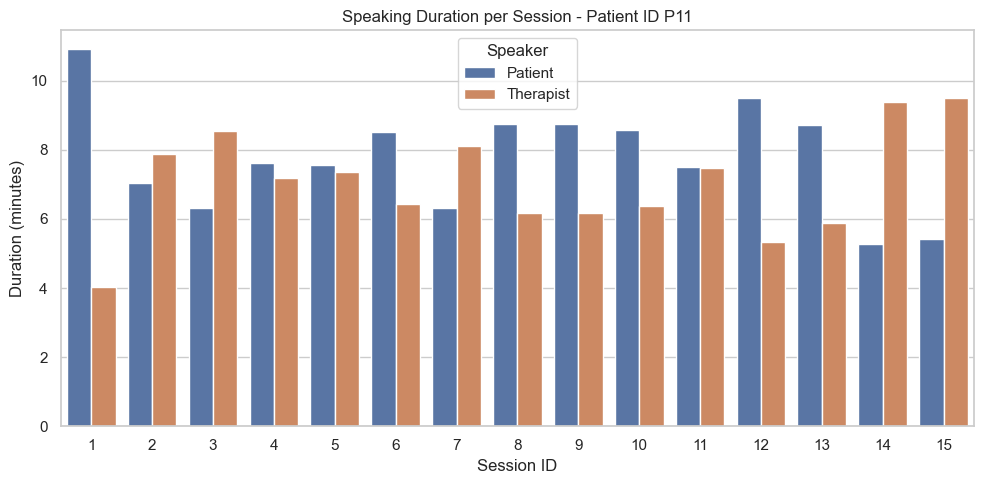

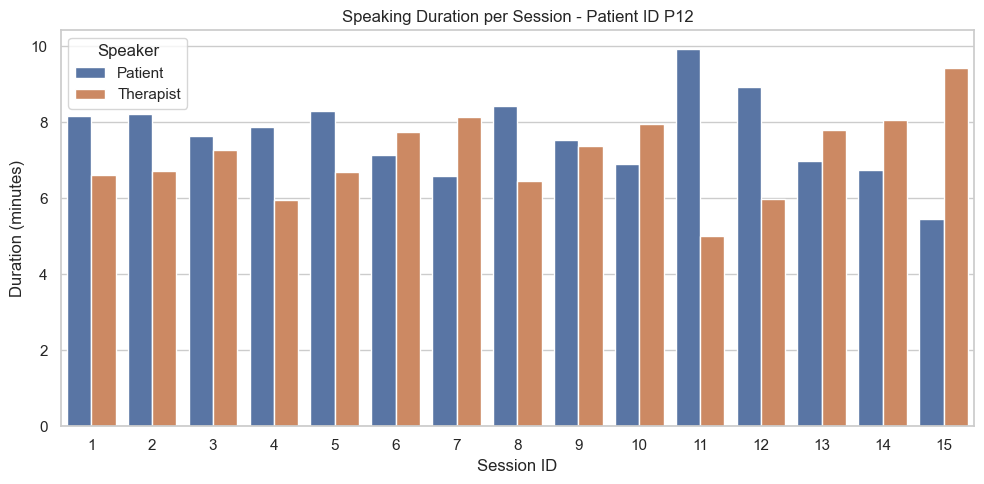

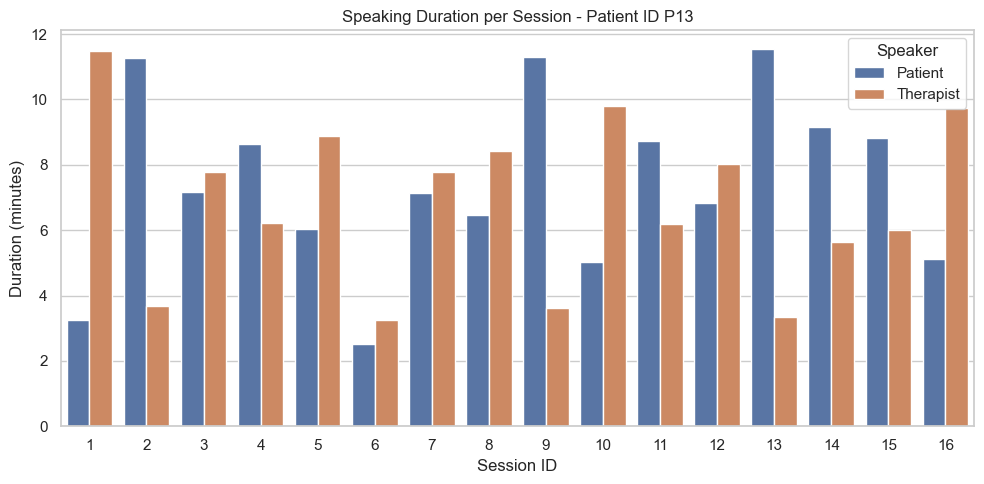

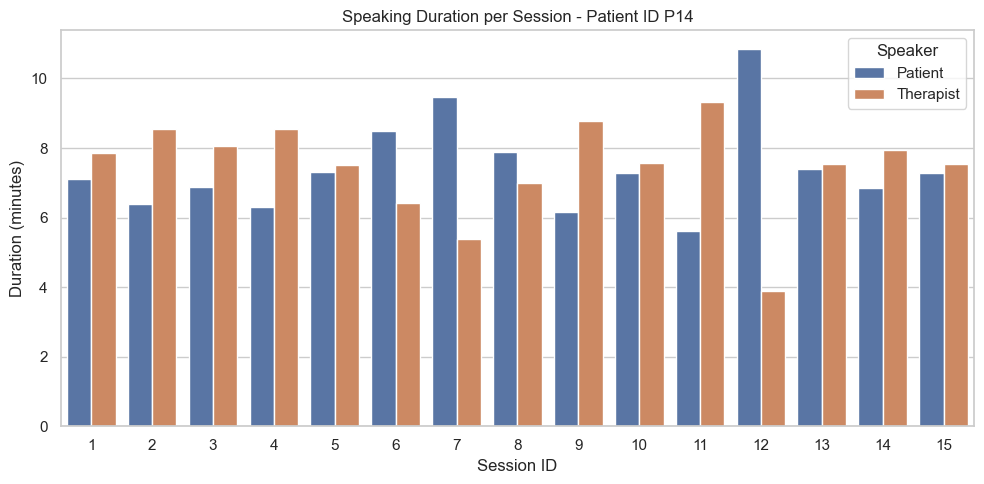

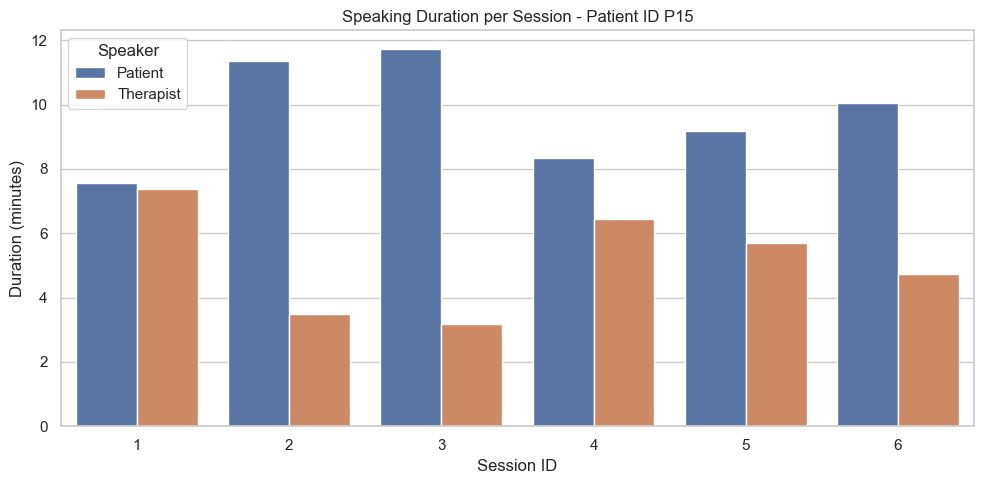

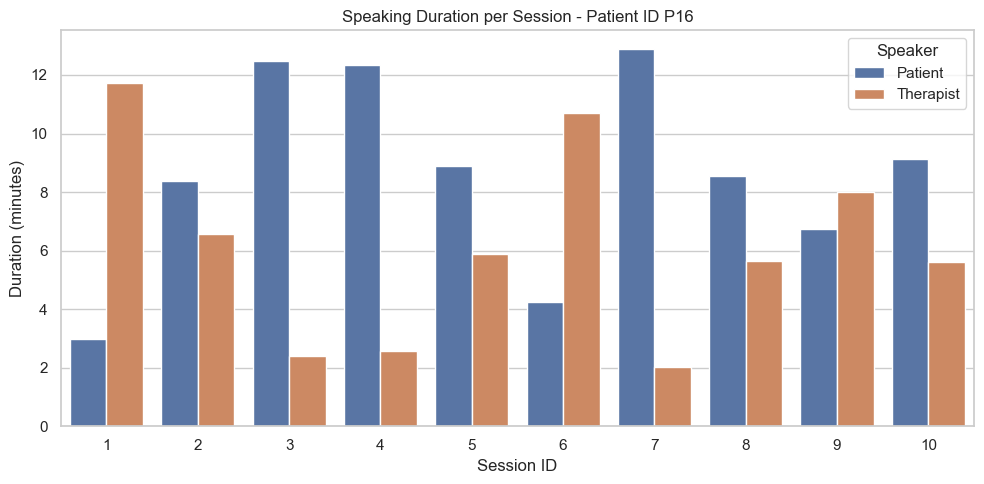

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = df_time

# Assume df is your DataFrame and already loaded
# Preprocess for plotting
df_sorted = df.sort_values(['patient_id', 'session_id'])

df_melted = df_sorted.melt(
    id_vars=['patient_id', 'session_id'],
    value_vars=['speaking duration patient', 'speaking duration of therapist'],
    var_name='Speaker',
    value_name='Duration'
)

df_melted['Speaker'] = df_melted['Speaker'].replace({
    'speaking duration patient': 'Patient',
    'speaking duration of therapist': 'Therapist'
})

df_melted['Duration'] = df_melted['Duration'] / 60
# Plot for each patient
patients = df_melted['patient_id'].unique()

for pid in patients:
    patient_data = df_melted[df_melted['patient_id'] == pid]

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=patient_data,
        x='session_id',
        y='Duration',
        hue='Speaker',
        errorbar=None  # No error bars
    )
    plt.title(f'Speaking Duration per Session - Patient ID {pid}')
    plt.xlabel('Session ID')
    plt.ylabel('Duration (minutes)')
    plt.legend(title='Speaker')
    plt.tight_layout()

    # ✅ Save the figure
    filename = f"Experiment_data/speaking_duration_patient_{pid}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures


   patient_id  session_id  speaking duration patient  \
0         P14           1                    425.747   
1         P14           2                    383.122   
2         P14           3                    412.194   
3         P14           4                    378.754   
4         P14           5                    439.394   
..        ...         ...                        ...   
72        P12          11                    595.637   
73        P12          12                    536.507   
74        P12          13                    419.160   
75        P12          14                    404.535   
76        P12          15                    326.753   

    speaking duration of therapist  \
0                          472.247   
1                          513.595   
2                          483.605   
3                          512.464   
4                          451.161   
..                             ...   
72                         300.342   
73                     

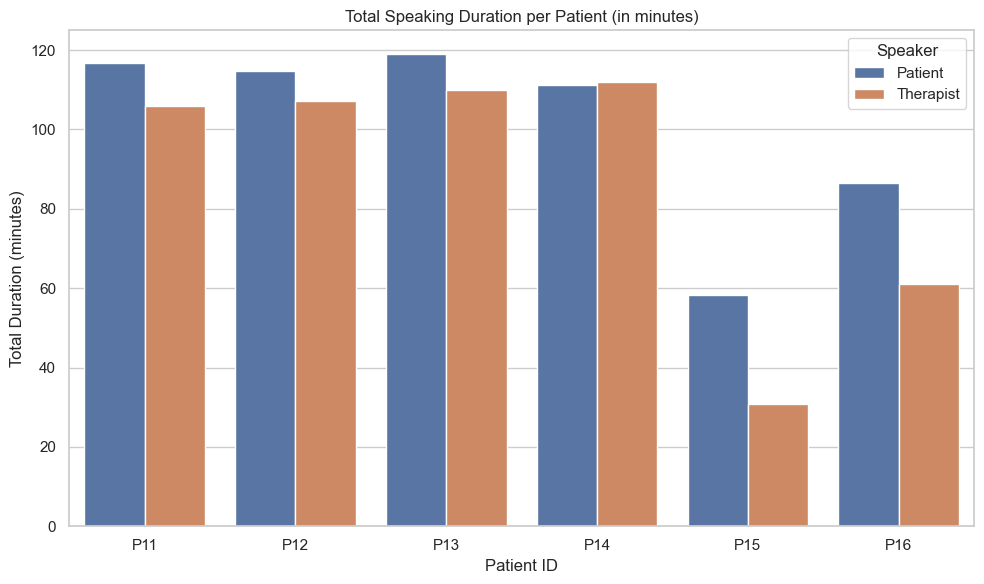

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_time is your DataFrame
print(df_time)
df = df_time

# Optional: Better visuals
sns.set(style="whitegrid")

# Group by patient_id and sum durations
df_total = df.groupby('patient_id')[['speaking duration patient', 'speaking duration of therapist']].sum().reset_index()

# Melt for plotting
df_total_melted = df_total.melt(
    id_vars='patient_id',
    value_vars=['speaking duration patient', 'speaking duration of therapist'],
    var_name='Speaker',
    value_name='Total Duration'
)

df_total_melted['Total Duration'] = df_total_melted['Total Duration'] / 60

# Clean names
df_total_melted['Speaker'] = df_total_melted['Speaker'].replace({
    'speaking duration patient': 'Patient',
    'speaking duration of therapist': 'Therapist'
})

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_total_melted,
    x='patient_id',
    y='Total Duration',
    hue='Speaker'
)
plt.title('Total Speaking Duration per Patient (in minutes)')
plt.xlabel('Patient ID')
plt.ylabel('Total Duration (minutes)')
plt.legend(title='Speaker')
plt.tight_layout()


# ✅ Save the total summary figure
plt.savefig("Experiment_data/total_speaking_duration_all_patients.pdf")
plt.show()
plt.close()

   patient id  session id  number of patient processes  \
0         P11           1                          117   
1         P11           2                           27   
2         P11           3                           43   
3         P11           4                           10   
4         P11           5                           57   
..        ...         ...                          ...   
72        P16           6                           23   
73        P16           7                           98   
74        P16           8                           54   
75        P16           9                           30   
76        P16          10                           75   

    number of therapist processes  % patient processes  % therapist processes  
0                              42            73.584906              26.415094  
1                              23            54.000000              46.000000  
2                              56            43.434343         

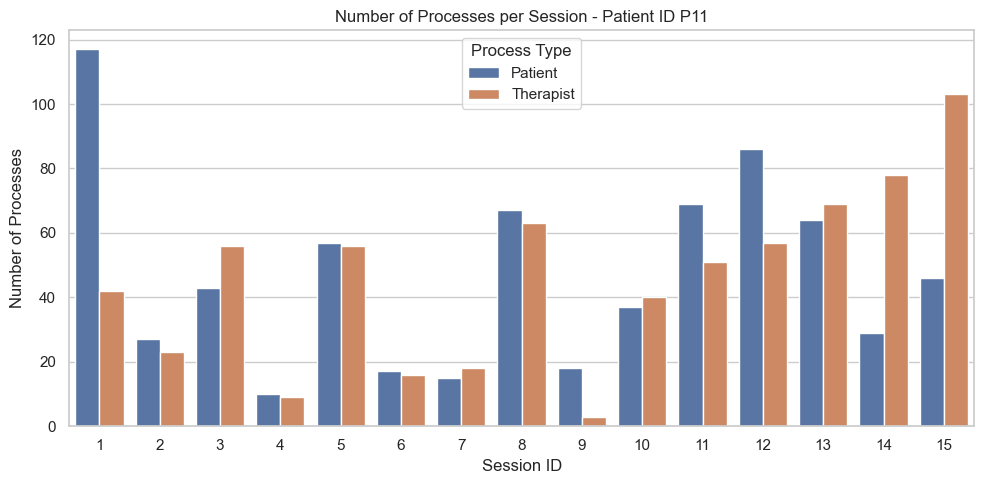

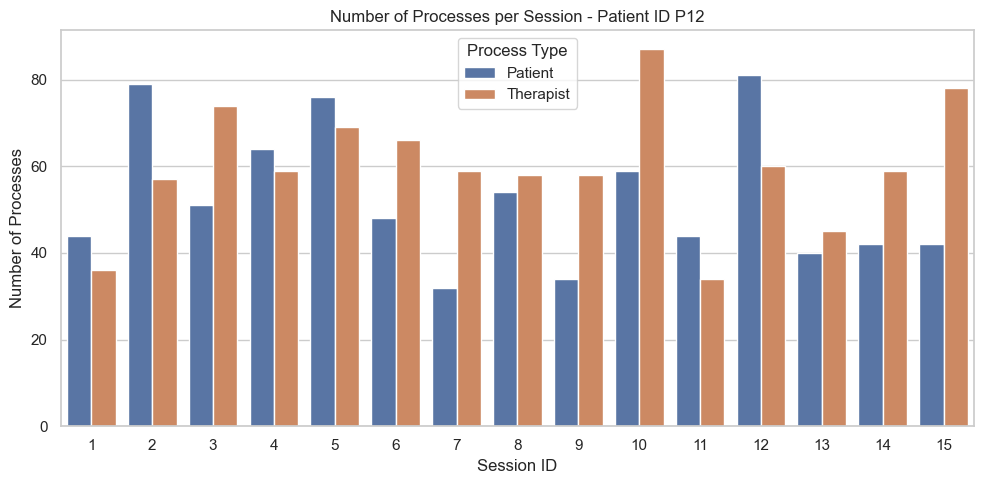

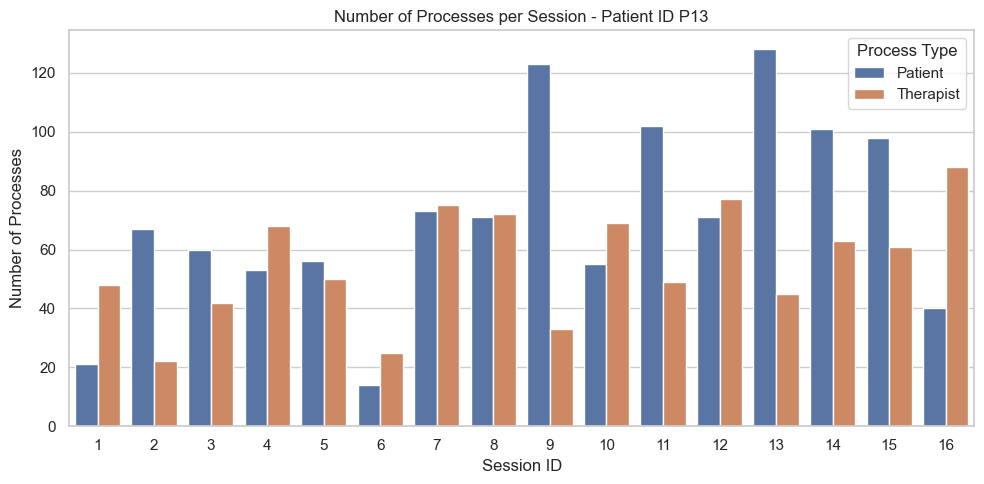

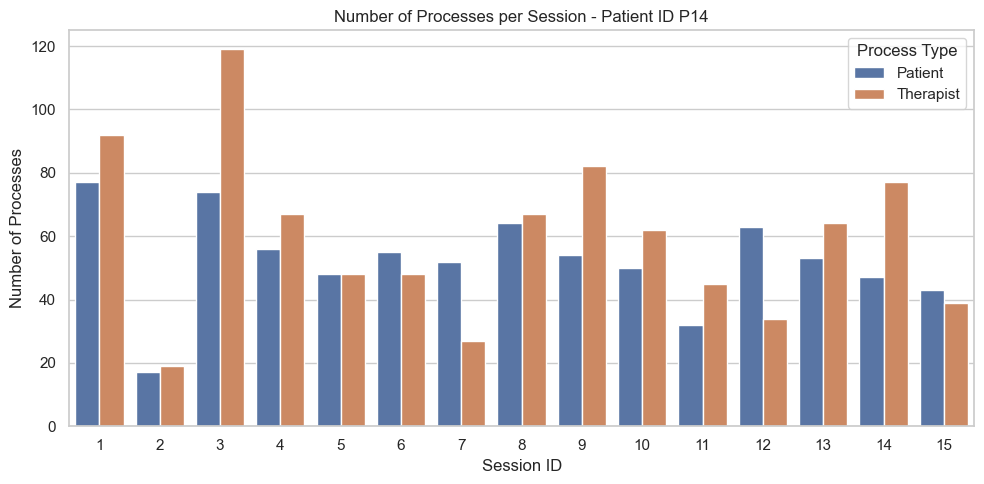

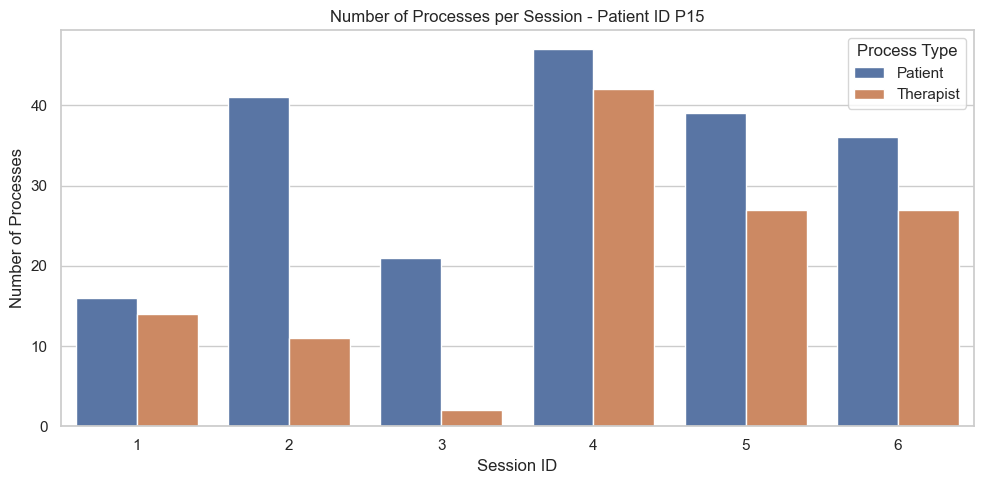

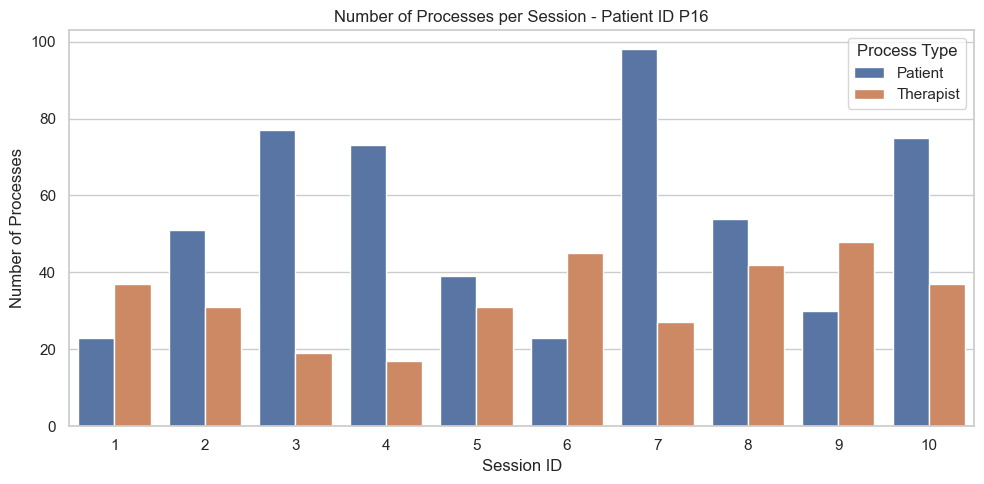

In [39]:
print(df_process)

df = df_process

# Melt to long format for Seaborn
df_melted = df.melt(
    id_vars=['patient id', 'session id'],
    value_vars=['number of patient processes', 'number of therapist processes'],
    var_name='Process Type',
    value_name='Count'
)

# Optional: clean up names for display
df_melted['Process Type'] = df_melted['Process Type'].replace({
    'number of patient processes': 'Patient',
    'number of therapist processes': 'Therapist'
})

# Plot for each patient
for pid in df_melted['patient id'].unique():
    patient_data = df_melted[df_melted['patient id'] == pid]

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=patient_data,
        x='session id',
        y='Count',
        hue='Process Type'
    )
    plt.title(f'Number of Processes per Session - Patient ID {pid}')
    plt.xlabel('Session ID')
    plt.ylabel('Number of Processes')
    plt.legend(title='Process Type')
    plt.tight_layout()
    # ✅ Save the figure
    filename = f"Experiment_data/number_of_processes_patient_and_therapist_{pid}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures

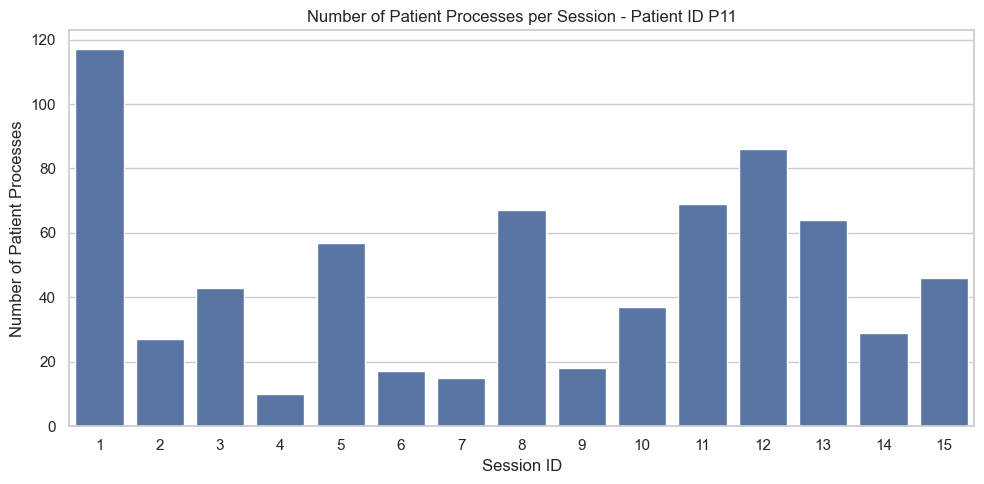

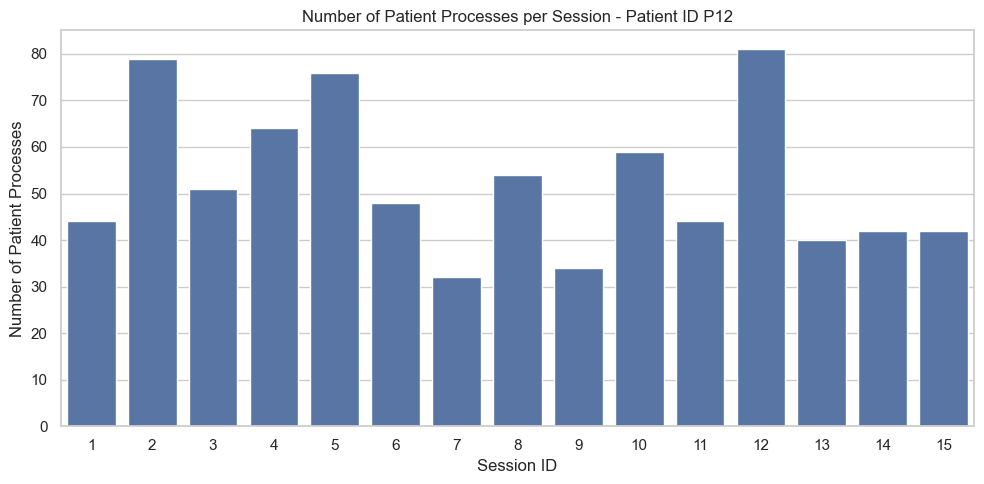

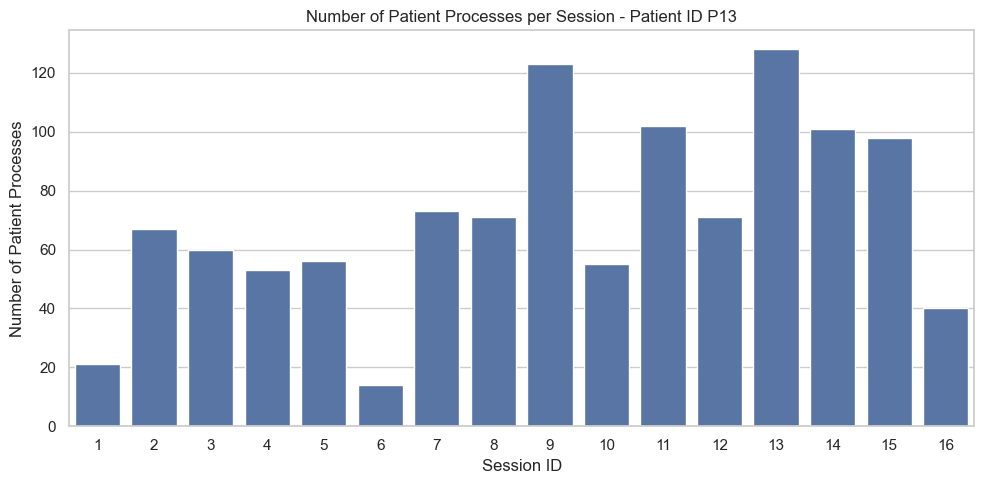

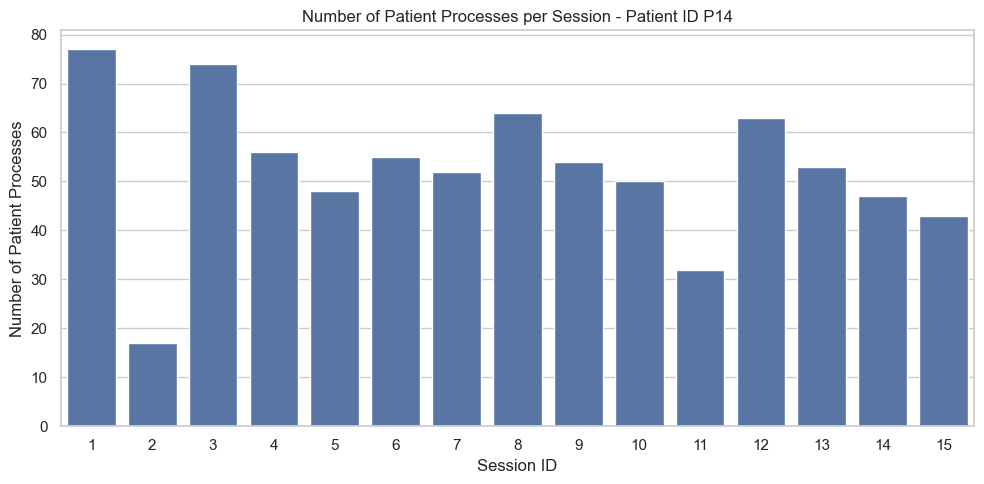

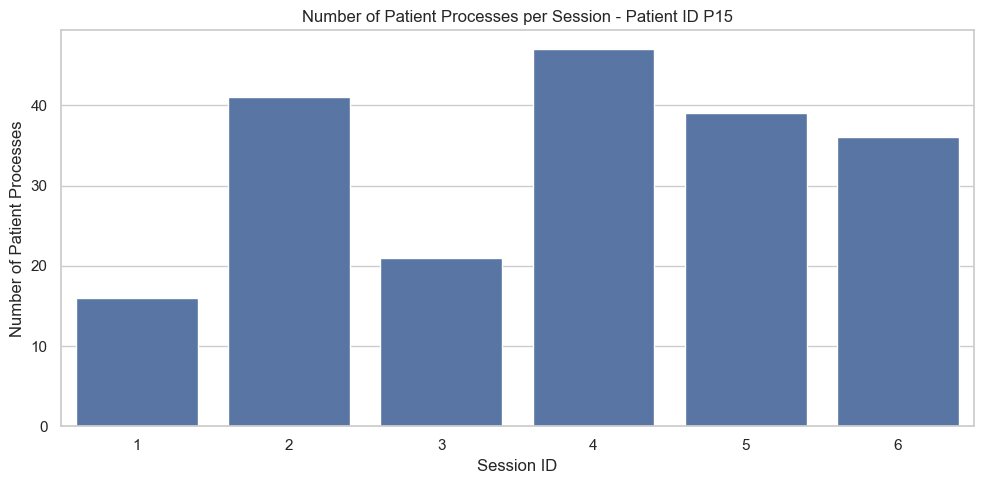

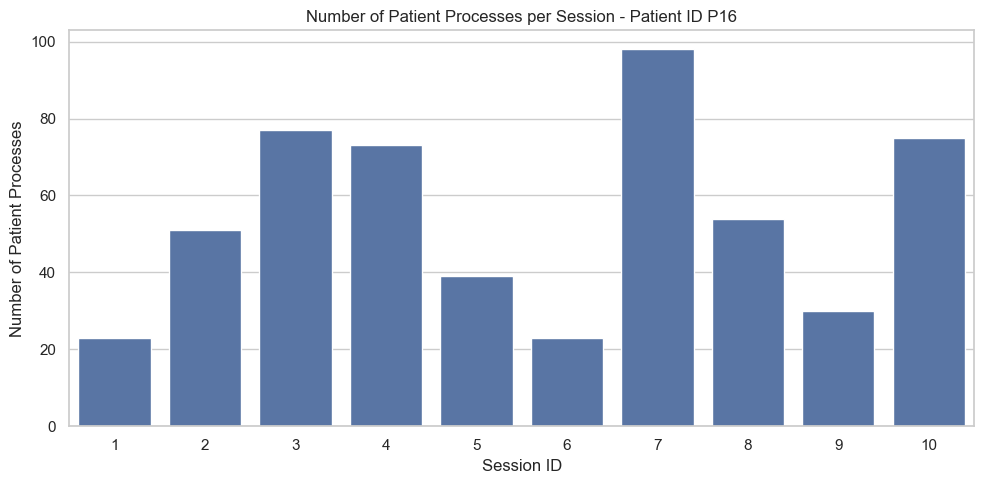

In [40]:
# Only patient processes
for pid in df['patient id'].unique():
    patient_data = df[df['patient id'] == pid]

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=patient_data,
        x='session id',
        y='number of patient processes'
    )
    plt.title(f'Number of Patient Processes per Session - Patient ID {pid}')
    plt.xlabel('Session ID')
    plt.ylabel('Number of Patient Processes')
    plt.tight_layout()
    # ✅ Save the figure
    filename = f"Experiment_data/number_of_processes_patient_{pid}.pdf"
    plt.savefig(filename)
    plt.show()
    plt.close()  # Close to avoid overlapping figures


# Analyzing how often Processes are in different Theme Clusters


In [15]:
import os
import json
import re
from collections import defaultdict

import os
import json
import re
from collections import defaultdict

def analyze_process_theme_distribution(base_folder='cluster_links/input_data/finalized_clusters'):
    process_theme_counts = defaultdict(set)  # Tracks which themes a process appears in (overall)
    patient_process_themes = defaultdict(lambda: defaultdict(set))  # Tracks per-patient theme occurrences

    for root, dirs, files in os.walk(base_folder):
        for filename in files:
            if not filename.endswith('.json') or filename.startswith('generated'):
                continue

            file_path = os.path.join(root, filename)

            # Match filenames like cluster_p01_s01.json
            match = re.match(r'cluster_(p\d+)_s\d+\.json', filename, re.IGNORECASE)
            if not match:
                continue

            patient_id = match.group(1).lower()

            with open(file_path, 'r', encoding='utf-8') as f:
                try:
                    data = json.load(f)
                except json.JSONDecodeError:
                    print(f"Warning: Failed to parse JSON in {file_path}")
                    continue

            for theme_key, theme_content in data.get("clusters", {}).items():
                theme_name = theme_content.get("Theme", theme_key)
                for process_entry in theme_content.get("Processes", []):
                    process_text = process_entry.get("Process", "").strip()
                    if process_text:
                        process_theme_counts[process_text].add(theme_name)
                        patient_process_themes[patient_id][process_text].add(theme_name)

    # Count how many themes each process appears in
    overall_counts = {p: len(t) for p, t in process_theme_counts.items()}
    patient_counts = {
        pid: {p: len(t) for p, t in proc.items()}
        for pid, proc in patient_process_themes.items()
    }

    # Calculate stats
    def compute_stats(counts_dict):
        total = len(counts_dict)
        multi_theme = sum(1 for v in counts_dict.values() if v > 1)
        percent_multi = (multi_theme / total * 100) if total > 0 else 0
        return {
            'total_processes': total,
            'multi_theme_processes': multi_theme,
            'percent_multi_theme': round(percent_multi, 2)
        }

    overall_stats = compute_stats(overall_counts)
    per_patient_stats = {
        pid: compute_stats(counts)
        for pid, counts in patient_counts.items()
    }

    return {
        'overall_counts': overall_counts,
        'patient_counts': patient_counts,
        'overall_stats': overall_stats,
        'per_patient_stats': per_patient_stats
    }



overall = analyze_process_theme_distribution()

print("Overall Theme Counts:")
print(overall)




Overall Theme Counts:
{'overall_counts': {'I could have had a rule there.': 2, "No, I don't have those rules, believe it or not.": 2, "It happens more when I'm doing something in the evening, like, if [SPOUSE]'s here for the evening and then leaves, then I don't get to zone into my own relaxation until, say, nine or eight thirty when it relieves.": 2, "So I'm going to read all my news.": 2, 'I just subscribe to a bunch of guys on Substack': 2, 'that are writing really well, that are interesting.': 2, 'And read those first, read some of the Washington Post headlines that I can stand, then get into my phone games.': 2, "And if I'm doing that, still on the couch, if it hits a certain hour, let's say ten-ish, I just fell into a hole and I might say, oh, crap, I just looked down and it's eleven thirty and I'm still in this hole.": 2, 'Okay, I do that.': 2, "So, yeah, that that bedtime rule is, is doesn't really work so much.": 2, 'My Insta reaction is always, who has that kind of time?': 2,

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_multi_theme_stats(results):
    # Define the mapping from p11–p16 to p1–p6
    patient_id_map = {f'p{str(i)}': f'p{i - 10}' for i in range(11, 17)}

    # Extract stats
    patient_stats = results['per_patient_stats']
    overall_stats = results['overall_stats']

    # Prepare DataFrame
    data = pd.DataFrame([
        {
            'Patient': patient_id_map.get(pid.lower(), pid.lower()).lower(),
            'Percent Multi-Theme': stats['percent_multi_theme'],
            'Total Processes': stats['total_processes']
        }
        for pid, stats in patient_stats.items()
    ])

    # Convert to uppercase for consistency in labels
    data['Patient'] = data['Patient'].str.upper()

    # Define desired order
    desired_order = [f'P{i}' for i in range(1, 7)]
    data['Patient'] = pd.Categorical(data['Patient'], categories=desired_order, ordered=True)
    data = data.sort_values('Patient')  # Ensures correct plotting order

    # Set font sizes globally (very large)
    plt.rcParams.update({
        'axes.titlesize': 28,
        'axes.labelsize': 24,
        'xtick.labelsize': 22,
        'ytick.labelsize': 22,
        'legend.fontsize': 20
    })

    # Plot
    plt.figure(figsize=(12, 7))
    sns.barplot(data=data, x='Patient', y='Percent Multi-Theme', palette='Blues_d')

    # Add overall average line
    plt.axhline(y=overall_stats['percent_multi_theme'], color='red', linestyle='--', label='Overall Avg')

    plt.title('Percentage of Processes Appearing in Multiple Themes (Per Patient)')
    plt.ylabel('Percent Multi-Theme (%)')
    plt.xlabel('Patient')
    plt.legend()
    plt.tight_layout()
    filename = f"Experiment_data/precentage_processes_mutiple_themes.pdf"
    plt.savefig(filename)
    plt.show()
